# Modelo base PV + BESS

Comparación del caso sin almacenamiento, tres reglas heurísticas y un despacho óptimo con previsión perfecta.

Caso de referencia de esta versión:

- PV: **100 MW**
- Demanda: **variable** (perfil horario de archivo)
- BESS: **30 MW / 120 MWh nominales**
- DoD: **80 %**
- RTE: **90 %**
- Sin generador convencional

Tarifa de compra: CU no residencial industrial sin contribución, Resolución CREG 119 de 2007, con opción horaria por nivel de tensión (Resolución CREG 079 de 1997). Solo se consideran los niveles 3 y 4.

El BESS se utiliza para atender la demanda del usuario y **no puede descargar hacia la red**. Los excedentes exportados provienen únicamente de la generación fotovoltaica.


## 1. Librerías

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# Generación solar simulada desde la irradiancia del TMY NSRDB.
import solar_tmy as ST

# Limpieza declarada de los cortes de medidor de la serie de carga.
import demanda as DEM

try:
    import pypsa
except ImportError:
    pypsa = None

# Si PyPSA no está instalado, ejecutar una vez y reiniciar el kernel:
# %pip install pypsa highspy

## 2. Lectura de datos

In [2]:
def buscar_archivo(*nombres):
    carpetas = [Path.cwd(), Path('/mnt/data')]

    for carpeta in carpetas:
        for nombre in nombres:
            archivo = carpeta / nombre
            if archivo.exists():
                return archivo

    raise FileNotFoundError(
        'No se encontró ninguno de estos archivos: ' + ', '.join(nombres)
    )


def leer_precio_bolsa(archivo, anio):
    df = pd.read_excel(archivo, header=2)
    df['Fecha'] = pd.to_datetime(df['Fecha'], errors='coerce')
    df = df.dropna(subset=['Fecha']).copy()

    horas = [str(h) for h in range(24)]
    faltantes = [h for h in horas if h not in df.columns]
    if faltantes:
        raise ValueError(f'Faltan columnas horarias en el precio de bolsa: {faltantes}')

    df = df.melt(
        id_vars=['Fecha'],
        value_vars=horas,
        var_name='Hora',
        value_name='Precio_Bolsa_COP_kWh',
    )

    df['Hora'] = pd.to_numeric(df['Hora'], errors='raise').astype(int)
    df['Precio_Bolsa_COP_kWh'] = pd.to_numeric(
        df['Precio_Bolsa_COP_kWh'], errors='raise'
    )
    df['Fecha'] = df['Fecha'] + pd.to_timedelta(df['Hora'], unit='h')

    df = (
        df.loc[
            df['Fecha'].dt.year == anio,
            ['Fecha', 'Precio_Bolsa_COP_kWh'],
        ]
        .sort_values('Fecha')
        .reset_index(drop=True)
    )

    if df['Fecha'].duplicated().any():
        raise ValueError('El precio de bolsa contiene horas duplicadas.')

    return df


def leer_perfil_pv(archivo, anio, pv_nominal_MW):
    df = pd.read_excel(
        archivo,
        sheet_name='Sheet1',
        usecols=['date', 'Generacion_MW'],
    )

    df['Fecha'] = pd.to_datetime(df['date'], errors='coerce')
    df['PV_MW'] = pd.to_numeric(df['Generacion_MW'], errors='coerce')

    df = (
        df.loc[
            df['Fecha'].dt.year == anio,
            ['Fecha', 'PV_MW'],
        ]
        .dropna()
        .sort_values('Fecha')
        .reset_index(drop=True)
    )

    df['PV_MW'] = df['PV_MW'].clip(lower=0)

    if df['Fecha'].duplicated().any():
        raise ValueError(f'{archivo.name}: hay fechas duplicadas.')

    if df['PV_MW'].max() > pv_nominal_MW * 1.10:
        raise ValueError(
            f'{archivo.name}: la potencia PV supera de forma inesperada el nominal.'
        )

    return df


def crear_serie_economica(
    anio,
    tarifa_cara_COP_kWh,
    tarifa_barata_COP_kWh,
    horas_caras,
    ppa_solar_COP_kWh,
    df_bolsa,
    cere_COP_MWh,
    fazni_COP_kWh,
    arranque_parada_COP_kWh,
):
    fechas = pd.date_range(
        f'{anio}-01-01 00:00',
        f'{anio}-12-31 23:00',
        freq='h',
    )

    df = pd.DataFrame({'Fecha': fechas})
    df['Hora'] = df['Fecha'].dt.hour
    df['Franja_alta'] = df['Hora'].isin(horas_caras)
    df['Franja_baja'] = ~df['Franja_alta']

    df['c_imp_COP_MWh'] = np.where(
        df['Franja_alta'],
        tarifa_cara_COP_kWh * 1000,
        tarifa_barata_COP_kWh * 1000,
    )
    df['c_ppa_COP_MWh'] = ppa_solar_COP_kWh * 1000

    df = df.merge(
        df_bolsa,
        on='Fecha',
        how='left',
        validate='one_to_one',
    )

    if df['Precio_Bolsa_COP_kWh'].isna().any():
        raise ValueError('Hay horas sin precio de bolsa.')

    cargos_variables_export_COP_MWh = (
        cere_COP_MWh
        + fazni_COP_kWh * 1000
        + arranque_parada_COP_kWh * 1000
    )

    df['c_exp_bruto_COP_MWh'] = df['Precio_Bolsa_COP_kWh'] * 1000
    df['c_exp_COP_MWh'] = (
        df['c_exp_bruto_COP_MWh']
        - cargos_variables_export_COP_MWh
    )

    return df


def leer_demanda_variable(
    archivo,
    anio,
    columna_carga,
):
    df = pd.read_csv(
        archivo,
        sep=';',
    )

    df['Fecha'] = pd.to_datetime(
        df['period'],
        dayfirst=True,
        errors='coerce',
    )

    df['Load_MW'] = pd.to_numeric(
        df[columna_carga],
        errors='coerce',
    )

    df = (
        df.loc[
            df['Fecha'].dt.year == anio,
            ['Fecha', 'Load_MW'],
        ]
        .dropna()
        .sort_values('Fecha')
        .reset_index(drop=True)
    )

    if df['Fecha'].duplicated().any():
        raise ValueError(
            'La curva de demanda contiene horas duplicadas.'
        )

    if (df['Load_MW'] < 0).any():
        raise ValueError(
            'La curva de demanda contiene valores negativos.'
        )

    return df


def preparar_caso(
    df_pv,
    df_load,
    df_economia,
):
    df = df_pv.merge(
        df_load,
        on='Fecha',
        how='left',
        validate='one_to_one',
    )

    if df['Load_MW'].isna().any():
        faltantes = int(
            df['Load_MW'].isna().sum()
        )

        raise ValueError(
            f'Faltan {faltantes} horas de demanda.'
        )

    df = df.merge(
        df_economia,
        on='Fecha',
        how='left',
        validate='one_to_one',
    )

    return df

## 3. Configuración del caso

In [3]:
# El caso base es la región UPME de Oriente. El recurso solar ya no se lee
# de un Excel de potencia: se simula desde el TMY de NSRDB con pvlib, en
# `solar_tmy.py`, que documenta orientación, DC/AC y pérdidas con su fuente.
sitio = 'Oriente'

archivo_precio_bolsa = buscar_archivo(
    'Precio_Bolsa_Nacional_($kwh)_2025.xlsx'
)

anio_simulacion = 2025


# ============================================================
# DEMANDA
# ============================================================

# Opciones:
# 'plana'
# 'variable'

tipo_demanda = 'variable'


# Demanda plana
demanda_plana_MW = 10.0


# Demanda variable
archivo_carga_nombre = 'load variable.csv'
columna_carga = 'Porvenir'


# ============================================================
# SISTEMA
# ============================================================

pv_nominal_MW = 100.0   # MWp (DC), la misma unidad del CAPEX en USD/kWp

power_MW = 30.0
capacity_MWh = 120.0

DoD = 0.80
eff_rt = 0.90
dt = 1.0

eff_c = np.sqrt(eff_rt)
eff_d = np.sqrt(eff_rt)

SOC_max = capacity_MWh
SOC_min = capacity_MWh * (1 - DoD)


# ============================================================
# HEURÍSTICAS
# ============================================================


hora_inicio_h2 = 18      # E2 arranca la descarga a esta hora y sigue hasta vaciar el BESS

# ============================================================
# COMPRA DE ENERGÍA
# ============================================================

# CU  industrial sin contribución. Res. CREG 119 de 2007.
# Solo N3 y N4: para 100 MW no aplican N1 ni N2.

nivel_tension = 3
opcion_tarifaria = 'opciones_horarias'   # 'monomia' | 'opciones_horarias' | 'doble_horaria'

CU_monomia_COP_kWh = {3: 652.7479, 4: 561.6795}

# 'horas_caras' = horas en que aplica la tarifa de la banda cara.
TARIFAS = {
    (3, 'opciones_horarias'): dict(
        cara=659.9496, barata=653.2247,
        horas_caras=set(range(6, 21)),  # Punta N3: 06:00 <= hora < 21:00
    ),
    (4, 'opciones_horarias'): dict(
        cara=574.0553, barata=561.8573,
        horas_caras={0} | set(range(21, 24)),
    ),
    (3, 'doble_horaria'): dict(
        cara=673.6197, barata=647.2871,
        horas_caras=set(range(19, 24)) | set(range(0, 6)),   # PENDIENTE: bandas reales
    ),
}


# ============================================================
# PPA SOLAR
# ============================================================

# Se paga sobre toda la energía PV disponible,
# incluso si una parte se vierte.

ppa_solar_COP_kWh = 300.0


# ============================================================
# VENTA DE EXCEDENTES
# ============================================================

cere_COP_MWh = 67_811.57
fazni_COP_kWh = 3.2695
arranque_parada_COP_kWh = 4.0


# ============================================================
# CND / ASIC
# ============================================================

cnd_asic_COP_kW_mes = 817.43
potencia_max_declarada_MW = 100.0


# ============================================================
# LÍMITE DE EXPORTACIÓN
# ============================================================

p_export_max_MW = pv_nominal_MW


# ============================================================
# OPTIMIZACIÓN
# ============================================================

c_epsilon_COP_MWh = 1.0
solver_name = 'highs'


# ============================================================
# PERIODO DE LAS GRÁFICAS
# ============================================================

fecha_inicio_grafica = '2025-03-06 00:00'
fecha_fin_grafica = '2025-03-15 00:00'


# ============================================================
# RESUMEN
# ============================================================

print(f'Caso: {sitio}')
print(f'PV: {pv_nominal_MW:.0f} MW')
print(f'Tipo de demanda: {tipo_demanda}')

if tipo_demanda == 'plana':
    print(
        f'Demanda plana: '
        f'{demanda_plana_MW:.2f} MW'
    )
else:
    print(
        f'Archivo de demanda: '
        f'{archivo_carga_nombre}'
    )

print(
    f'BESS: {power_MW:.0f} MW / '
    f'{capacity_MWh:.0f} MWh'
)

print(
    f'SOC: {SOC_min:.0f}–'
    f'{SOC_max:.0f} MWh'
)

print(
    f'RTE: {eff_rt:.0%} | '
    f'DoD: {DoD:.0%}'
)

Caso: Oriente
PV: 100 MW
Tipo de demanda: variable
Archivo de demanda: load variable.csv
BESS: 30 MW / 120 MWh
SOC: 24–120 MWh
RTE: 90% | DoD: 80%


## 4. Preparación de las series

In [4]:
# ============================================================
# PRECIO DE BOLSA
# ============================================================

df_bolsa = leer_precio_bolsa(
    archivo_precio_bolsa,
    anio_simulacion,
)


# ============================================================
# GENERACIÓN PV
# ============================================================

# `pv_nominal_MW` es potencia DC; la AC de la planta es MWp / DC-AC, que es
# donde recorta el inversor. El perfil se calcula una vez y se cachea.
df_pv = ST.perfil_pv(
    sitio,
    pv_nominal_MW,
    anio=anio_simulacion,
)


# ============================================================
# DEMANDA
# ============================================================

if tipo_demanda == 'plana':

    df_load = df_pv[
        ['Fecha']
    ].copy()

    df_load['Load_MW'] = (
        demanda_plana_MW
    )


elif tipo_demanda == 'variable':

    archivo_carga = buscar_archivo(
        archivo_carga_nombre
    )

    df_load = leer_demanda_variable(
        archivo=archivo_carga,
        anio=anio_simulacion,
        columna_carga=columna_carga,
    )

    # La serie trae 71 horas exactamente en 0 MW en 11 rachas de hasta
    # 22 h: son cortes de medidor, no consumo. Se imputan con la mediana
    # de la misma hora del día en los días válidos vecinos. Las horas
    # bajas dispersas NO se tocan: pueden ser paradas reales de planta.
    df_load = DEM.limpiar(df_load)


else:

    raise ValueError(
        "tipo_demanda debe ser "
        "'plana' o 'variable'."
    )


# ============================================================
# SERIE ECONÓMICA
# ============================================================

if opcion_tarifaria == 'monomia':
    _cu = CU_monomia_COP_kWh[nivel_tension]
    tarifa_cara_COP_kWh = _cu
    tarifa_barata_COP_kWh = _cu
    horas_caras = set()
else:
    _t = TARIFAS[(nivel_tension, opcion_tarifaria)]
    tarifa_cara_COP_kWh = _t['cara']
    tarifa_barata_COP_kWh = _t['barata']
    horas_caras = _t['horas_caras']

df_economia = crear_serie_economica(
    anio_simulacion,
    tarifa_cara_COP_kWh,
    tarifa_barata_COP_kWh,
    horas_caras,
    ppa_solar_COP_kWh,
    df_bolsa,
    cere_COP_MWh,
    fazni_COP_kWh,
    arranque_parada_COP_kWh,
)

# ============================================================
# CONSTRUCCIÓN DEL CASO
# ============================================================

df_base = preparar_caso(
    df_pv,
    df_load,
    df_economia,
)


# ============================================================
# GUARDA DE COMPLETITUD
# ============================================================

horas_esperadas = len(
    pd.date_range(
        f'{anio_simulacion}-01-01 00:00',
        f'{anio_simulacion}-12-31 23:00',
        freq='h',
    )
)

if len(df_base) != horas_esperadas:
    raise ValueError(
        f'El caso tiene {len(df_base):,} horas y se esperaban '
        f'{horas_esperadas:,}. Revisar el perfil PV o la demanda.'
    )


# ============================================================
# LÍMITE DE IMPORTACIÓN
# ============================================================

p_import_max_MW = (
    df_base['Load_MW'].max()
    + power_MW
)


# ============================================================
# COSTOS DE EXPORTACIÓN
# ============================================================

cargos_variables_export = (
    cere_COP_MWh
    + fazni_COP_kWh * 1000
    + arranque_parada_COP_kWh * 1000
)


costo_fijo_cnd_asic_anual_COP = (
    cnd_asic_COP_kW_mes
    * potencia_max_declarada_MW
    * 1000
    * df_base[
        'Fecha'
    ].dt.to_period('M').nunique()
)


# ============================================================
# CARACTERIZACIÓN DE LA DEMANDA
# ============================================================

demanda_media = (
    df_base['Load_MW'].mean()
)

demanda_maxima = (
    df_base['Load_MW'].max()
)

demanda_minima = (
    df_base['Load_MW'].min()
)

factor_carga = (
    demanda_media
    / demanda_maxima
)

energia_demanda_GWh = (
    df_base['Load_MW'].sum()
    * dt
    / 1000
)


# ============================================================
# RESUMEN
# ============================================================

print(
    f'Tipo de demanda: '
    f'{tipo_demanda}'
)

print(
    f'Horas del caso: '
    f'{len(df_base):,}'
)

print(
    f'Generación PV: '
    f'{df_base["PV_MW"].sum() * dt / 1000:,.1f} GWh'
)

print(
    f'Demanda anual: '
    f'{energia_demanda_GWh:,.1f} GWh'
)

print(
    f'Demanda media: '
    f'{demanda_media:,.2f} MW'
)

print(
    f'Demanda máxima: '
    f'{demanda_maxima:,.2f} MW'
)

print(
    f'Demanda mínima: '
    f'{demanda_minima:,.2f} MW'
)

print(
    f'Factor de carga: '
    f'{factor_carga:.3f}'
)

print(
    f'Límite de importación: '
    f'{p_import_max_MW:,.2f} MW'
)

print(
    f'Precio medio de bolsa: '
    f'{df_bolsa["Precio_Bolsa_COP_kWh"].mean():,.1f} '
    f'COP/kWh'
)

print(
    f'Cargos variables de exportación: '
    f'{cargos_variables_export:,.2f} COP/MWh'
)

print(
    f'CND/ASIC anual: '
    f'{costo_fijo_cnd_asic_anual_COP / 1e9:,.3f} '
    f'mil millones COP'
)

print(
    f'Horas con precio neto de exportación negativo: '
    f'{(df_base["c_exp_COP_MWh"] < 0).sum():,}'
)

Tipo de demanda: variable
Horas del caso: 8,760
Generación PV: 138.7 GWh
Demanda anual: 158.7 GWh
Demanda media: 18.12 MW
Demanda máxima: 23.23 MW
Demanda mínima: 0.13 MW
Factor de carga: 0.780
Límite de importación: 53.23 MW
Precio medio de bolsa: 240.8 COP/kWh
Cargos variables de exportación: 75,081.07 COP/MWh
CND/ASIC anual: 0.981 mil millones COP
Horas con precio neto de exportación negativo: 0


### 4.1. Caracterización de la demanda


CARACTERIZACIÓN DE LA DEMANDA
Demanda media      : 18.12 MW
Demanda máxima     : 23.23 MW
Demanda mínima     : 0.13 MW
Factor de carga    : 0.780
Horas en 0 MW      : 0
Horas < 5 MW       : 102


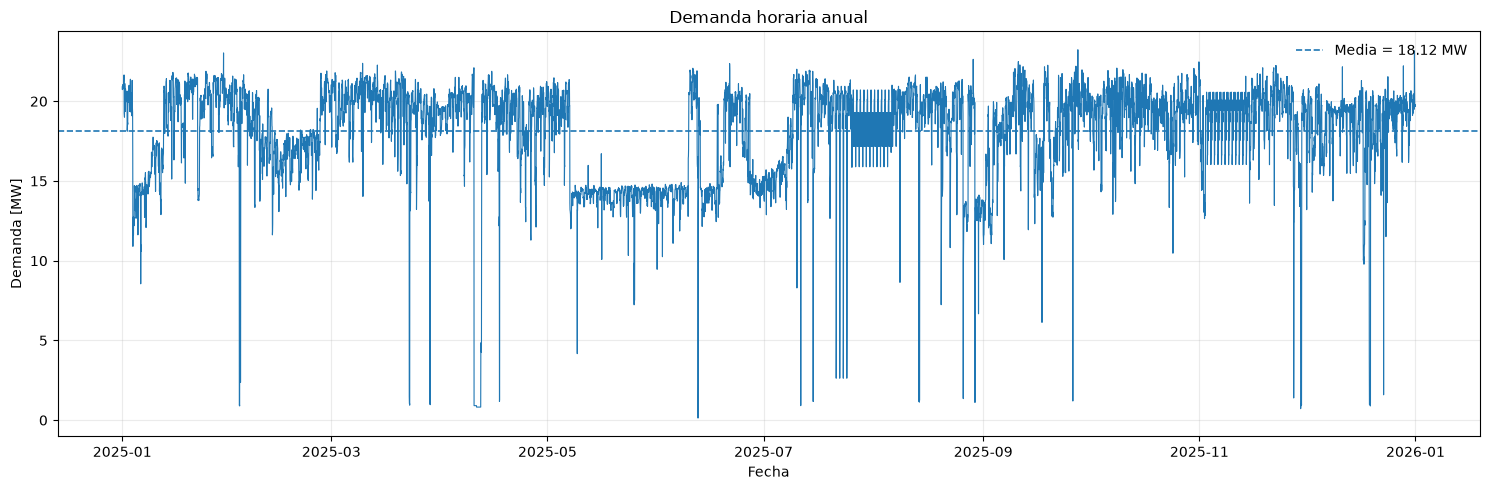

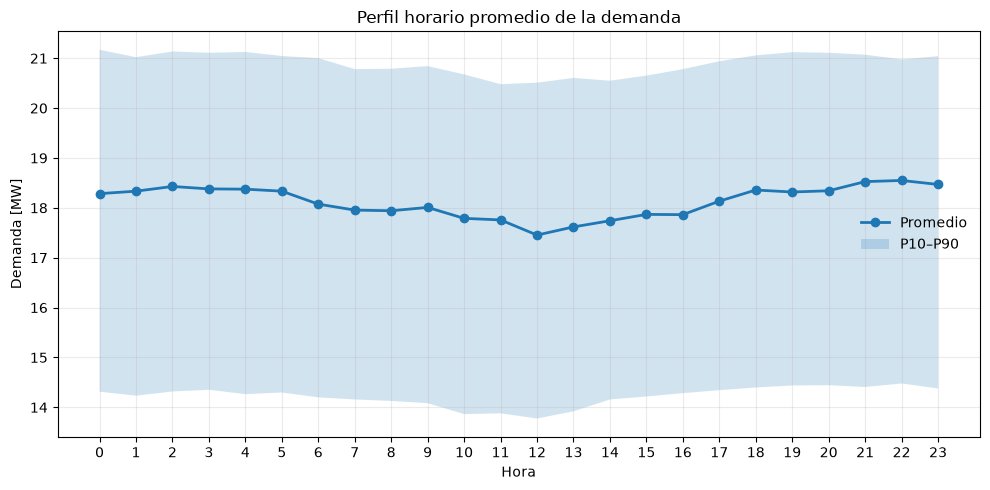

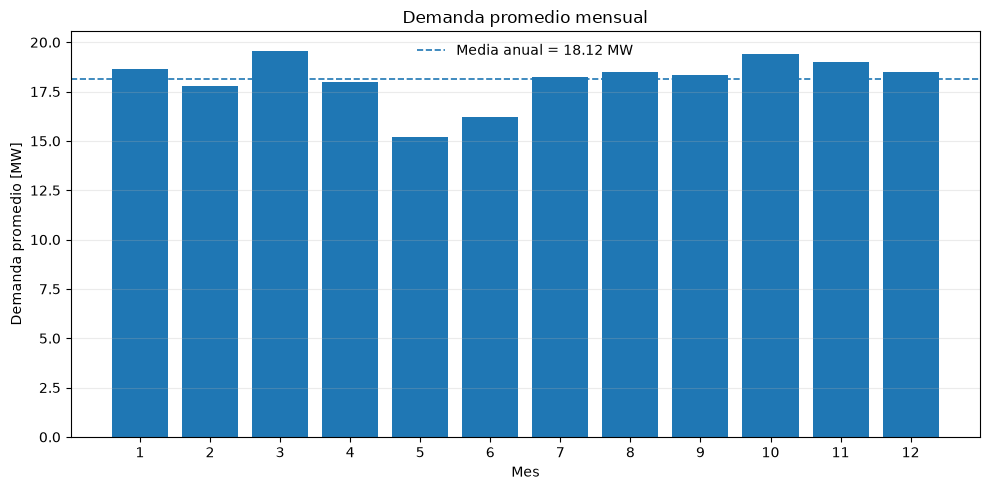

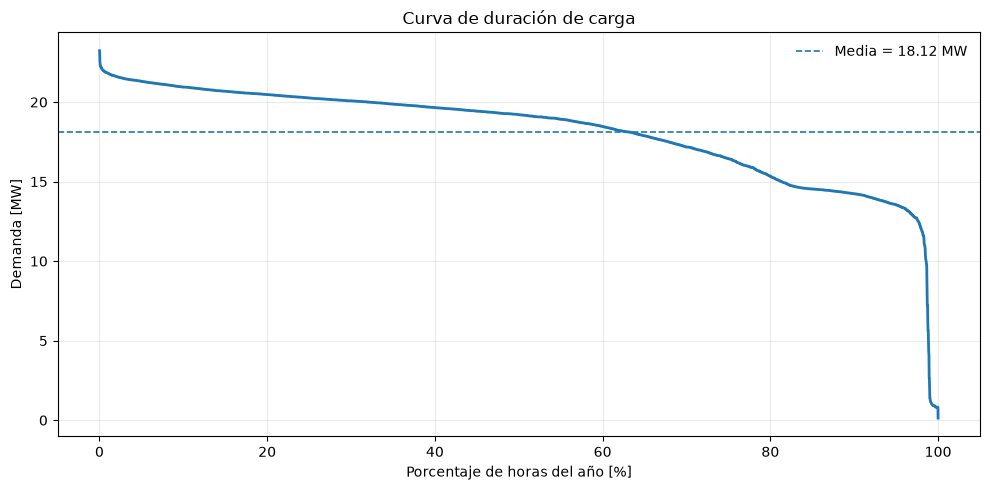

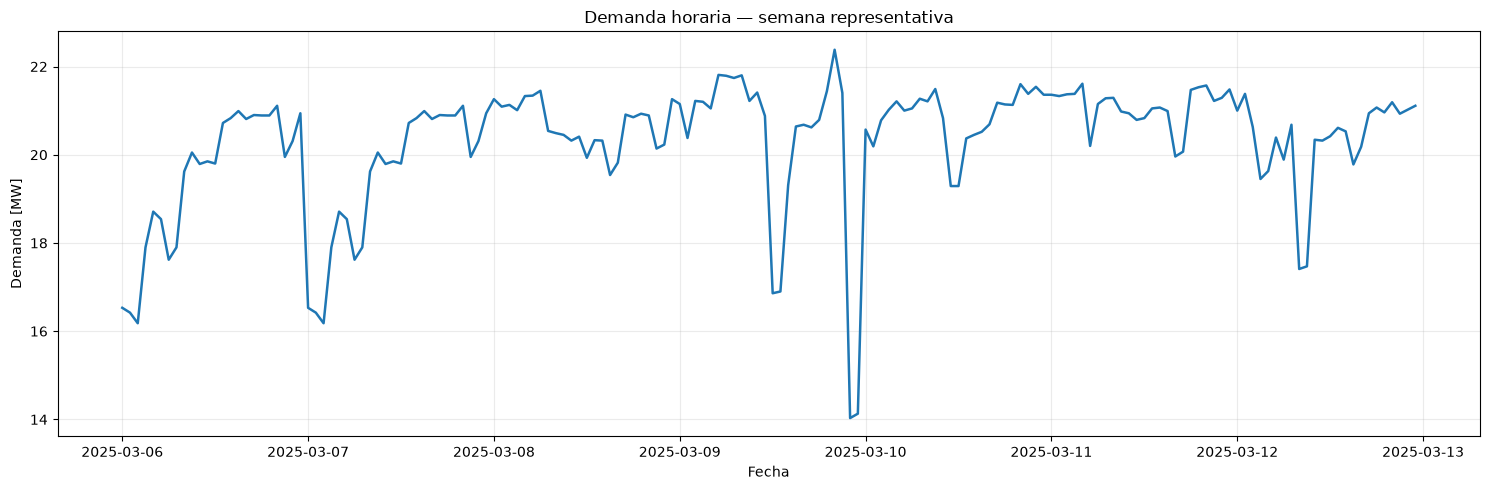

In [5]:
# ============================================================
# ANÁLISIS DE LA DEMANDA
# ============================================================

# ------------------------------------------------------------
# Estadísticas principales
# ------------------------------------------------------------

demanda_media = df_base['Load_MW'].mean()
demanda_maxima = df_base['Load_MW'].max()
demanda_minima = df_base['Load_MW'].min()

factor_carga = (
    demanda_media
    / demanda_maxima
)

horas_cero = (
    df_base['Load_MW'] == 0
).sum()

horas_menor_5 = (
    df_base['Load_MW'] < 5
).sum()


print('=' * 70)
print('CARACTERIZACIÓN DE LA DEMANDA')
print('=' * 70)

print(
    f'Demanda media      : {demanda_media:.2f} MW'
)

print(
    f'Demanda máxima     : {demanda_maxima:.2f} MW'
)

print(
    f'Demanda mínima     : {demanda_minima:.2f} MW'
)

print(
    f'Factor de carga    : {factor_carga:.3f}'
)

print(
    f'Horas en 0 MW      : {horas_cero}'
)

print(
    f'Horas < 5 MW       : {horas_menor_5}'
)


# ============================================================
# 1. SERIE ANUAL
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 5)
)

ax.plot(
    df_base['Fecha'],
    df_base['Load_MW'],
    linewidth=0.8
)

ax.axhline(
    demanda_media,
    linestyle='--',
    linewidth=1.2,
    label=f'Media = {demanda_media:.2f} MW'
)

ax.set_title(
    'Demanda horaria anual'
)

ax.set_xlabel(
    'Fecha'
)

ax.set_ylabel(
    'Demanda [MW]'
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ============================================================
# 2. PERFIL PROMEDIO POR HORA
# ============================================================

perfil_horario = (
    df_base
    .assign(
        Hora=df_base['Fecha'].dt.hour
    )
    .groupby('Hora')['Load_MW']
    .agg(
        Media='mean',
        P10=lambda x: x.quantile(0.10),
        P90=lambda x: x.quantile(0.90),
    )
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    perfil_horario['Hora'],
    perfil_horario['Media'],
    marker='o',
    linewidth=2,
    label='Promedio'
)

ax.fill_between(
    perfil_horario['Hora'],
    perfil_horario['P10'],
    perfil_horario['P90'],
    alpha=0.2,
    label='P10–P90'
)

ax.set_title(
    'Perfil horario promedio de la demanda'
)

ax.set_xlabel(
    'Hora'
)

ax.set_ylabel(
    'Demanda [MW]'
)

ax.set_xticks(
    range(0, 24)
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ============================================================
# 3. DEMANDA PROMEDIO MENSUAL
# ============================================================

demanda_mensual = (
    df_base
    .assign(
        Mes=df_base['Fecha'].dt.month
    )
    .groupby('Mes')['Load_MW']
    .mean()
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    demanda_mensual.index,
    demanda_mensual.values
)

ax.axhline(
    demanda_media,
    linestyle='--',
    linewidth=1.2,
    label=f'Media anual = {demanda_media:.2f} MW'
)

ax.set_title(
    'Demanda promedio mensual'
)

ax.set_xlabel(
    'Mes'
)

ax.set_ylabel(
    'Demanda promedio [MW]'
)

ax.set_xticks(
    range(1, 13)
)

ax.grid(
    axis='y',
    alpha=0.25
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. CURVA DE DURACIÓN DE CARGA
# ============================================================

demanda_ordenada = (
    df_base['Load_MW']
    .sort_values(
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

porcentaje_horas = (
    np.arange(
        1,
        len(demanda_ordenada) + 1
    )
    / len(demanda_ordenada)
    * 100
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    porcentaje_horas,
    demanda_ordenada,
    linewidth=2
)

ax.axhline(
    demanda_media,
    linestyle='--',
    linewidth=1.2,
    label=f'Media = {demanda_media:.2f} MW'
)

ax.set_title(
    'Curva de duración de carga'
)

ax.set_xlabel(
    'Porcentaje de horas del año [%]'
)

ax.set_ylabel(
    'Demanda [MW]'
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. SEMANA REPRESENTATIVA
# ============================================================

inicio_semana = pd.Timestamp(
    fecha_inicio_grafica
)

fin_semana = (
    inicio_semana
    + pd.Timedelta(days=7)
)

mask = (
    (df_base['Fecha'] >= inicio_semana)
    &
    (df_base['Fecha'] < fin_semana)
)

fig, ax = plt.subplots(
    figsize=(15, 5)
)

ax.plot(
    df_base.loc[
        mask,
        'Fecha'
    ],
    df_base.loc[
        mask,
        'Load_MW'
    ],
    linewidth=1.8
)

ax.set_title(
    'Demanda horaria — semana representativa'
)

ax.set_xlabel(
    'Fecha'
)

ax.set_ylabel(
    'Demanda [MW]'
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

## 5. Estrategias heurísticas

Las tres estrategias usan los mismos límites físicos. La condición anual de estado de carga es cíclica: el SOC al final del horizonte debe coincidir con el SOC inicial.

`Franja_alta` designa la **banda cara** de la tarifa, que en los niveles 3 y 4 corresponde a horas nocturnas.

- **E1 — Autoconsumo:** carga con excedente PV y descarga ante déficit.
- **E2 — Desplazamiento solar:** carga con excedente PV y arranca la descarga a `hora_inicio_h2`, sosteniéndola hasta agotar la energía útil del BESS o hasta que reaparezca el excedente solar. No tiene hora de cierre: la descarga la termina el estado de carga, no el reloj ni la banda tarifaria.
- **E3 — Estrategia tarifaria:** carga con excedente PV a cualquier hora, después del autoconsumo; la red solo puede complementar la carga en las horas inmediatamente anteriores al inicio de la banda cara y únicamente si el diferencial de tarifa compensa las pérdidas del BESS. Descarga únicamente en la banda cara.

Si el precio neto de exportación es negativo, el excedente no almacenado se vierte.


In [6]:
def simular_heuristica_una_vuelta(
    df_base,
    estrategia,
    soc_inicial_MWh,
    power_MW,
    SOC_min,
    SOC_max,
    eff_c,
    eff_d,
    eff_rt,
    dt,
    hora_inicio_h2,
    horas_caras,
    precio_alto_COP_MWh,
    p_import_max_MW,
    p_export_max_MW,
    tol=1e-8,
):
    df = df_base.copy()

    df['PV_to_Load_MW'] = np.minimum(df['PV_MW'], df['Load_MW'])
    df['PV_Net_Surplus_MW'] = (df['PV_MW'] - df['Load_MW']).clip(lower=0)
    df['Residual_Load_MW'] = (df['Load_MW'] - df['PV_MW']).clip(lower=0)

    columnas_cero = [
        'Charge_from_PV_MW',
        'Charge_from_Grid_MW',
        'Charge_MW',
        'Discharge_MW',
        'Grid_to_Load_MW',
        'Grid_Import_MW',
        'Grid_Export_MW',
        'Curtailment_MW',
    ]
    for columna in columnas_cero:
        df[columna] = 0.0

    df['SOC_MWh'] = np.nan

    if estrategia == 'Sin BESS':
        df['Grid_to_Load_MW'] = df['Residual_Load_MW']
        df['Grid_Import_MW'] = df['Grid_to_Load_MW']

        excedente = df['PV_Net_Surplus_MW']
        exportar = df['c_exp_COP_MWh'] > 0
        df['Grid_Export_MW'] = np.where(
            exportar,
            np.minimum(excedente, p_export_max_MW),
            0.0,
        )
        df['Curtailment_MW'] = excedente - df['Grid_Export_MW']
        return df

    soc = float(soc_inicial_MWh)

    charge_pv = []
    charge_grid = []
    charge_total = []
    discharge = []
    soc_hist = []
    grid_to_load = []
    grid_import = []
    export = []
    curtailment = []

    # E2: latch de descarga. Se arma a hora_inicio_h2 y se desarma cuando el
    # BESS queda vacío o cuando vuelve a haber excedente solar. No tiene hora
    # de cierre: la descarga la termina el estado de carga, no el reloj.
    descarga_activa = False

    usable_cap = SOC_max - SOC_min
    n_horas_carga_red = int(
        np.ceil(usable_cap / (power_MW * eff_c * dt))
    )

    # Horas en las que arranca un bloque de banda cara. Puede haber más de uno
    # (una tarifa de doble banda tiene pico de mañana y de noche), así que se
    # abre ventana de carga antes de cada uno y no solo antes del primero.
    inicios_banda_cara = {
        h for h in horas_caras if (h - 1) % 24 not in horas_caras
    }

    ventana_carga_red_horas = {
        (inicio - k) % 24
        for inicio in inicios_banda_cara
        for k in range(1, n_horas_carga_red + 1)
    } - horas_caras

    for row in df.itertuples(index=False):
        fecha = row.Fecha
        hora = fecha.hour
        pv = row.PV_MW
        load = row.Load_MW

        pv_to_load = min(pv, load)
        excedente_pv = max(0.0, pv - pv_to_load)
        demanda_residual = max(0.0, load - pv_to_load)

        ch_pv = 0.0
        ch_grid = 0.0
        dis = 0.0

        if estrategia == 'E1 — Autoconsumo':
            if excedente_pv > 0:
                espacio = max(0.0, SOC_max - soc)
                ch_pv = min(
                    excedente_pv,
                    power_MW,
                    espacio / (eff_c * dt),
                )
                soc += ch_pv * eff_c * dt

            elif demanda_residual > 0:
                disponible = max(0.0, soc - SOC_min)
                dis = min(
                    demanda_residual,
                    power_MW,
                    disponible * eff_d / dt,
                )
                soc -= dis / eff_d * dt

        elif estrategia == 'E2 — Desplazamiento solar':
            if hora == hora_inicio_h2:
                descarga_activa = True

            if excedente_pv > 0:
                descarga_activa = False
                espacio = max(0.0, SOC_max - soc)
                ch_pv = min(
                    excedente_pv,
                    power_MW,
                    espacio / (eff_c * dt),
                )
                soc += ch_pv * eff_c * dt

            elif (
                descarga_activa
                and demanda_residual > 0
                and soc > SOC_min + tol
            ):
                disponible = max(0.0, soc - SOC_min)
                dis = min(
                    demanda_residual,
                    power_MW,
                    disponible * eff_d / dt,
                )
                soc -= dis / eff_d * dt

            if soc <= SOC_min + tol:
                soc = SOC_min
                descarga_activa = False

        elif estrategia == 'E3 — Estrategia tarifaria':
            # Con tarifa monómica no hay banda que discriminar: toda hora con
            # déficit vale lo mismo, así que la regla tarifaria degenera en
            # autoconsumo, que es su límite económico correcto. Sin esto E3
            # no descargaría nunca y quedaría en cero sin avisar.
            if horas_caras:
                momento_de_cargar = excedente_pv > 0 or row.Franja_baja
                momento_de_descargar = row.Franja_alta
            else:
                momento_de_cargar = excedente_pv > 0
                momento_de_descargar = excedente_pv <= 0

            if momento_de_cargar:
                # Primero se utiliza el excedente solar.
                if excedente_pv > 0:
                    espacio = max(0.0, SOC_max - soc)
                    ch_pv = min(
                        excedente_pv,
                        power_MW,
                        espacio / (eff_c * dt),
                    )
                    soc += ch_pv * eff_c * dt

                # La red solo complementa la carga antes de la franja alta
                # y únicamente si el arbitraje cubre las pérdidas del BESS.
                ventana_carga_red = hora in ventana_carga_red_horas
                carga_red_economica = (
                    row.c_imp_COP_MWh / eff_rt < precio_alto_COP_MWh
                )

                if ventana_carga_red and carga_red_economica:
                    espacio = max(0.0, SOC_max - soc)
                    potencia_disponible = max(0.0, power_MW - ch_pv)
                    ch_grid = min(
                        potencia_disponible,
                        espacio / (eff_c * dt),
                    )
                    soc += ch_grid * eff_c * dt

            elif momento_de_descargar and demanda_residual > 0:
                disponible = max(0.0, soc - SOC_min)
                dis = min(
                    demanda_residual,
                    power_MW,
                    disponible * eff_d / dt,
                )
                soc -= dis / eff_d * dt

        else:
            raise ValueError(f'Estrategia no reconocida: {estrategia}')

        gl = max(0.0, demanda_residual - dis)
        gi = gl + ch_grid

        if gi > p_import_max_MW + tol:
            raise ValueError(
                f'{estrategia}: la importación supera el límite del PCC.'
            )

        excedente_restante = max(0.0, excedente_pv - ch_pv)
        if row.c_exp_COP_MWh > 0:
            ex = min(excedente_restante, p_export_max_MW)
        else:
            ex = 0.0
        curt = max(0.0, excedente_restante - ex)

        charge_pv.append(ch_pv)
        charge_grid.append(ch_grid)
        charge_total.append(ch_pv + ch_grid)
        discharge.append(dis)
        soc_hist.append(soc)
        grid_to_load.append(gl)
        grid_import.append(gi)
        export.append(ex)
        curtailment.append(curt)

    df['Charge_from_PV_MW'] = charge_pv
    df['Charge_from_Grid_MW'] = charge_grid
    df['Charge_MW'] = charge_total
    df['Discharge_MW'] = discharge
    df['SOC_MWh'] = soc_hist
    df['Grid_to_Load_MW'] = grid_to_load
    df['Grid_Import_MW'] = grid_import
    df['Grid_Export_MW'] = export
    df['Curtailment_MW'] = curtailment

    df.attrs['SOC_inicial_MWh'] = float(soc_inicial_MWh)
    df.attrs['SOC_final_MWh'] = float(soc_hist[-1])

    return df


def simular_heuristica_ciclica(
    df_base,
    estrategia,
    SOC_min,
    SOC_max,
    tol_ciclico=1e-5,
    max_iter=30,
    **kwargs,
):
    """Busca el SOC periódico de la regla y ejecuta el año desde ese estado."""
    if estrategia == 'Sin BESS':
        return simular_heuristica_una_vuelta(
            df_base=df_base,
            estrategia=estrategia,
            soc_inicial_MWh=SOC_min,
            SOC_min=SOC_min,
            SOC_max=SOC_max,
            **kwargs,
        )

    soc_ini = float(SOC_min)

    for _ in range(max_iter):
        df = simular_heuristica_una_vuelta(
            df_base=df_base,
            estrategia=estrategia,
            soc_inicial_MWh=soc_ini,
            SOC_min=SOC_min,
            SOC_max=SOC_max,
            **kwargs,
        )

        soc_fin = float(df['SOC_MWh'].iloc[-1])
        if abs(soc_fin - soc_ini) <= tol_ciclico:
            # "Batería llena y quieta" también es un punto fijo del mapa, y sin
            # este aviso se reportaría como un resultado válido de 0 % de ahorro.
            if df['Discharge_MW'].sum() + df['Charge_MW'].sum() <= tol_ciclico:
                print(
                    f'AVISO — {estrategia}: el SOC cíclico convergió sin ningún '
                    f'ciclo (SOC fijo en {soc_fin:,.1f} MWh). La regla no está '
                    f'operando el BESS; revisa la configuración tarifaria.'
                )
            df.attrs['SOC_inicial_MWh'] = soc_ini
            df.attrs['SOC_final_MWh'] = soc_fin
            return df

        soc_ini = float(np.clip(soc_fin, SOC_min, SOC_max))

    raise RuntimeError(
        f'{estrategia}: no convergió la condición cíclica de SOC.'
    )

In [7]:
def validar_resultado(
    df,
    estrategia,
    power_MW,
    SOC_min,
    SOC_max,
    eff_c,
    eff_d,
    dt,
    p_import_max_MW,
    p_export_max_MW,
    tol=1e-5,
):
    if estrategia != 'Sin BESS':
        if (df['SOC_MWh'] < SOC_min - tol).any():
            raise ValueError(f'{estrategia}: SOC por debajo del mínimo.')
        if (df['SOC_MWh'] > SOC_max + tol).any():
            raise ValueError(f'{estrategia}: SOC por encima del máximo.')
        if (df['Charge_MW'] > power_MW + tol).any():
            raise ValueError(f'{estrategia}: potencia de carga excedida.')
        if (df['Discharge_MW'] > power_MW + tol).any():
            raise ValueError(f'{estrategia}: potencia de descarga excedida.')
        if ((df['Charge_MW'] > tol) & (df['Discharge_MW'] > tol)).any():
            raise ValueError(f'{estrategia}: carga y descarga simultánea.')

        soc_ini = df.attrs.get('SOC_inicial_MWh', np.nan)
        soc_fin = float(df['SOC_MWh'].iloc[-1])
        if not np.isfinite(soc_ini) or abs(soc_fin - soc_ini) > 1e-4:
            raise ValueError(f'{estrategia}: no cumple SOC inicial = SOC final.')

    if (df['Grid_Import_MW'] > p_import_max_MW + tol).any():
        raise ValueError(f'{estrategia}: importación por encima del límite.')
    if (df['Grid_Export_MW'] > p_export_max_MW + tol).any():
        raise ValueError(f'{estrategia}: exportación por encima del límite.')
    if ((df['Grid_Import_MW'] > tol) & (df['Grid_Export_MW'] > tol)).any():
        raise ValueError(f'{estrategia}: importación y exportación simultáneas.')

    balance_pv = (
        df['PV_MW']
        - df['PV_to_Load_MW']
        - df['Charge_from_PV_MW']
        - df['Grid_Export_MW']
        - df['Curtailment_MW']
    )

    balance_demanda = (
        df['Load_MW']
        - df['PV_to_Load_MW']
        - df['Discharge_MW']
        - df['Grid_to_Load_MW']
    )

    balance_global = (
        df['PV_MW']
        + df['Grid_Import_MW']
        + df['Discharge_MW']
        - df['Load_MW']
        - df['Charge_MW']
        - df['Grid_Export_MW']
        - df['Curtailment_MW']
    )

    if not np.allclose(balance_pv, 0.0, atol=tol):
        raise ValueError(f'{estrategia}: falla el balance PV.')
    if not np.allclose(balance_demanda, 0.0, atol=tol):
        raise ValueError(f'{estrategia}: falla el balance de demanda.')
    if not np.allclose(balance_global, 0.0, atol=tol):
        raise ValueError(f'{estrategia}: falla el balance global.')

    if estrategia != 'Sin BESS':
        soc = df['SOC_MWh'].to_numpy()
        soc_prev = np.r_[df.attrs['SOC_inicial_MWh'], soc[:-1]]
        delta_teorico = (
            df['Charge_MW'].to_numpy() * eff_c * dt
            - df['Discharge_MW'].to_numpy() / eff_d * dt
        )
        error_soc = soc - soc_prev - delta_teorico

        if np.max(np.abs(error_soc)) > 1e-4:
            raise ValueError(f'{estrategia}: falla la dinámica del SOC.')


def resumir_resultado(
    df,
    sitio,
    estrategia,
    costo_fijo_cnd_asic_COP,
    c_epsilon_COP_MWh,
    dt=1.0,
):
    pv = df['PV_MW'].sum() * dt
    load = df['Load_MW'].sum() * dt
    pv_directo = df['PV_to_Load_MW'].sum() * dt
    pv_bess = df['Charge_from_PV_MW'].sum() * dt
    carga_red = df['Charge_from_Grid_MW'].sum() * dt
    carga = df['Charge_MW'].sum() * dt
    descarga = df['Discharge_MW'].sum() * dt
    grid_load = df['Grid_to_Load_MW'].sum() * dt
    importacion = df['Grid_Import_MW'].sum() * dt
    exportacion = df['Grid_Export_MW'].sum() * dt
    vertimiento = df['Curtailment_MW'].sum() * dt

    # El PPA se paga sobre toda la generación PV disponible.
    costo_ppa = (
        df['c_ppa_COP_MWh'] * df['PV_MW'] * dt
    ).sum()

    costo_importacion = (
        df['c_imp_COP_MWh'] * df['Grid_Import_MW'] * dt
    ).sum()

    ingreso_exportacion = (
        df['c_exp_COP_MWh'] * df['Grid_Export_MW'] * dt
    ).sum()

    costo_regularizacion = (
        c_epsilon_COP_MWh
        * (df['Charge_MW'] + df['Discharge_MW'])
        * dt
    ).sum()

    costo_despacho_variable = (
        costo_importacion
        - ingreso_exportacion
        + costo_regularizacion
    )

    costo_total = (
        costo_ppa
        + costo_fijo_cnd_asic_COP
        + costo_despacho_variable
    )

    return {
        'Sitio': sitio,
        'Estrategia': estrategia,
        'Demanda_MWh': load,
        'Generacion_PV_MWh': pv,
        'PV_directo_MWh': pv_directo,
        'PV_a_BESS_MWh': pv_bess,
        'Carga_desde_red_MWh': carga_red,
        'Carga_BESS_MWh': carga,
        'Descarga_BESS_MWh': descarga,
        'Importacion_demanda_MWh': grid_load,
        'Importacion_MWh': importacion,
        'Exportacion_MWh': exportacion,
        'Vertimiento_MWh': vertimiento,
        'Aprovechamiento_solar_%': (1 - vertimiento / pv) * 100 if pv > 0 else np.nan,
        'Cobertura_demanda_%': (1 - grid_load / load) * 100 if load > 0 else np.nan,
        'SOC_inicial_MWh': (
            np.nan if estrategia == 'Sin BESS'
            else float(df.attrs['SOC_inicial_MWh'])
        ),
        'SOC_final_MWh': (
            np.nan if estrategia == 'Sin BESS'
            else float(df['SOC_MWh'].iloc[-1])
        ),
        'Costo_PPA_COP': costo_ppa,
        'Costo_importacion_COP': costo_importacion,
        'Ingreso_exportacion_COP': ingreso_exportacion,
        'Costo_regularizacion_COP': costo_regularizacion,
        'Costo_fijo_CND_ASIC_COP': costo_fijo_cnd_asic_COP,
        'Costo_despacho_variable_COP': costo_despacho_variable,
        'Costo_total_suministro_COP': costo_total,
    }


def agregar_ahorro(resumen):
    base = (
        resumen.loc[
            resumen['Estrategia'] == 'Sin BESS',
            ['Sitio', 'Costo_total_suministro_COP'],
        ]
        .rename(
            columns={
                'Costo_total_suministro_COP': 'Costo_sin_BESS_COP'
            }
        )
    )

    resumen = resumen.merge(
        base,
        on='Sitio',
        how='left',
        validate='many_to_one',
    )

    resumen['Ahorro_vs_sin_BESS_COP'] = (
        resumen['Costo_sin_BESS_COP']
        - resumen['Costo_total_suministro_COP']
    )
    resumen['Ahorro_vs_sin_BESS_%'] = (
        resumen['Ahorro_vs_sin_BESS_COP']
        / resumen['Costo_sin_BESS_COP']
        * 100
    )

    return resumen

In [8]:
estrategias_heuristicas = [
    'Sin BESS',
    'E1 — Autoconsumo',
    'E2 — Desplazamiento solar',
    'E3 — Estrategia tarifaria',
]

resultados = {}
filas = []

precio_alto_COP_MWh = tarifa_cara_COP_kWh * 1000

for estrategia in estrategias_heuristicas:
    df_resultado = simular_heuristica_ciclica(
        df_base=df_base,
        estrategia=estrategia,
        SOC_min=SOC_min,
        SOC_max=SOC_max,
        power_MW=power_MW,
        eff_c=eff_c,
        eff_d=eff_d,
        eff_rt=eff_rt,
        dt=dt,
        hora_inicio_h2=hora_inicio_h2,
        horas_caras=horas_caras,
        precio_alto_COP_MWh=precio_alto_COP_MWh,
        p_import_max_MW=p_import_max_MW,
        p_export_max_MW=p_export_max_MW,
    )

    validar_resultado(
        df_resultado,
        estrategia,
        power_MW,
        SOC_min,
        SOC_max,
        eff_c,
        eff_d,
        dt,
        p_import_max_MW,
        p_export_max_MW,
    )

    resultados[(sitio, estrategia)] = df_resultado
    filas.append(
        resumir_resultado(
            df_resultado,
            sitio,
            estrategia,
            costo_fijo_cnd_asic_anual_COP,
            c_epsilon_COP_MWh,
            dt,
        )
    )

resumen = agregar_ahorro(pd.DataFrame(filas))

columnas_resumen = [
    'Estrategia',
    'Importacion_MWh',
    'Exportacion_MWh',
    'Vertimiento_MWh',
    'Carga_BESS_MWh',
    'Descarga_BESS_MWh',
    'Cobertura_demanda_%',
    'Costo_total_suministro_COP',
    'Ahorro_vs_sin_BESS_%',
]

display(
    resumen[columnas_resumen]
    .style
    .format({
        'Importacion_MWh': '{:,.0f}',
        'Exportacion_MWh': '{:,.0f}',
        'Vertimiento_MWh': '{:,.0f}',
        'Carga_BESS_MWh': '{:,.0f}',
        'Descarga_BESS_MWh': '{:,.0f}',
        'Cobertura_demanda_%': '{:,.2f}',
        'Costo_total_suministro_COP': '{:,.0f}',
        'Ahorro_vs_sin_BESS_%': '{:,.2f}',
    })
    .hide(axis='index')
)

Estrategia,Importacion_MWh,Exportacion_MWh,Vertimiento_MWh,Carga_BESS_MWh,Descarga_BESS_MWh,Cobertura_demanda_%,Costo_total_suministro_COP,Ahorro_vs_sin_BESS_%
Sin BESS,"97,364","77,364",0,0,0,38.67,"94,123,707,292",0.00
E1 — Autoconsumo,"65,675","42,154",0,"35,210","31,689",58.63,"77,965,124,039",17.17
E2 — Desplazamiento solar,"65,911","42,417",0,"34,947","31,453",58.48,"78,138,494,167",16.98
E3 — Estrategia tarifaria,"67,134","43,775",0,"33,589","30,230",57.71,"78,696,106,412",16.39


## 6. Despacho óptimo con PyPSA

La optimización usa previsión perfecta sobre el año completo.

La batería se representa con un **Store** y dos **Links** independientes para carga y descarga. El SOC es cíclico. La generación PV es una disponibilidad máxima, por lo que el modelo puede verter energía.

Para impedir que el BESS venda energía, la exportación se conecta al bus PV y el enlace PV → usuario es unidireccional. La red de suministro se conecta al bus del usuario. Una variable binaria por hora impide importar y exportar simultáneamente en el punto de conexión.

El PPA y el CND/ASIC son costos comunes al escenario y se agregan en la evaluación económica; no intervienen en la decisión de despacho.

In [9]:
def optimizar_pypsa(
    df_base,
    power_MW,
    SOC_min,
    SOC_max,
    eff_c,
    eff_d,
    pv_nominal_MW,
    p_import_max_MW,
    p_export_max_MW,
    solver_name='highs',
    c_epsilon_COP_MWh=1.0,
    tol=1e-6,
    # Se deja configurable porque con BESS grande bajo tarifa regulada el
    # árbol de ramificación de las binarias del punto de conexión se
    # dispara. Para barridos conviene aflojarlo a 1e-5: sobre un costo
    # anual del orden de 90 mil millones de COP es menos de 1 millón.
    mip_rel_gap=1e-7,
):
    if pypsa is None:
        raise ImportError(
            'PyPSA no está instalado. Ejecuta %pip install pypsa highspy '
            'y reinicia el kernel.'
        )

    data = (
        df_base
        .copy()
        .set_index('Fecha')
        .sort_index()
    )
    snapshots = data.index

    # Si el perfil supera el nominal, se amplia p_nom en vez de recortar la serie:
    # de lo contrario el optimo veria menos energia que las heuristicas.
    pv_p_nom = float(max(pv_nominal_MW, data['PV_MW'].max()))

    pv_pu = (
        data['PV_MW'] / pv_p_nom
    ).clip(lower=0.0, upper=1.0)

    n = pypsa.Network()
    n.set_snapshots(snapshots)

    n.add('Carrier', 'electricidad')
    n.add('Carrier', 'bateria')

    n.add('Bus', 'PV', carrier='electricidad')
    n.add('Bus', 'Usuario', carrier='electricidad')
    n.add('Bus', 'BESS', carrier='bateria')

    # Disponibilidad solar. El costo del PPA no entra en el despacho.
    n.add(
        'Generator',
        'PV_disponible',
        bus='PV',
        p_nom=pv_p_nom,
        p_min_pu=0.0,
        p_max_pu=pv_pu,
        marginal_cost=0.0,
    )

    # Enlace unidireccional: el PV puede atender al usuario y cargar el BESS,
    # pero el BESS no tiene camino físico hacia el bus de exportación.
    n.add(
        'Link',
        'PV_a_usuario',
        bus0='PV',
        bus1='Usuario',
        p_nom=pv_p_nom,
        p_min_pu=0.0,
        p_max_pu=1.0,
        efficiency=1.0,
    )

    # Excedentes PV.
    n.add(
        'Generator',
        'Exportacion_PV',
        bus='PV',
        sign=-1,
        p_nom=p_export_max_MW,
        p_min_pu=0.0,
        p_max_pu=1.0,
        marginal_cost=-data['c_exp_COP_MWh'],
    )

    n.add(
        'Load',
        'Demanda',
        bus='Usuario',
        p_set=data['Load_MW'],
    )

    n.add(
        'Generator',
        'Importacion_red',
        bus='Usuario',
        p_nom=p_import_max_MW,
        p_min_pu=0.0,
        p_max_pu=1.0,
        marginal_cost=data['c_imp_COP_MWh'],
    )

    # Energía almacenada en MWh. El Store conserva la capacidad nominal
    # y el SOC mínimo se representa mediante e_min_pu.
    n.add(
        'Store',
        'BESS_store',
        bus='BESS',
        e_nom=SOC_max,
        e_min_pu=SOC_min / SOC_max,
        e_max_pu=1.0,
        e_cyclic=True,
        standing_loss=0.0,
    )

    # Carga: la potencia se mide en el bus del usuario.
    n.add(
        'Link',
        'BESS_carga',
        bus0='Usuario',
        bus1='BESS',
        p_nom=power_MW,
        p_min_pu=0.0,
        p_max_pu=1.0,
        efficiency=eff_c,
        marginal_cost=c_epsilon_COP_MWh,
    )

    # Descarga: power_MW corresponde a la potencia útil entregada al usuario.
    n.add(
        'Link',
        'BESS_descarga',
        bus0='BESS',
        bus1='Usuario',
        p_nom=power_MW / eff_d,
        p_min_pu=0.0,
        p_max_pu=1.0,
        efficiency=eff_d,
        marginal_cost=c_epsilon_COP_MWh * eff_d,
    )

    def restricciones_pcc(network, sns):
        m = network.model
        p = m.variables['Generator-p']

        # La exclusividad importación/exportación solo puede ser vinculante en
        # las horas en que exportar pagaría más que importar Y hay sol. En el
        # resto es redundante: si hubiera importación p_i > 0 y exportación
        # p_e > 0 a la vez, bajar ambas en delta cambia el costo en
        # delta * (c_exp - c_imp) <= 0 y deja los dos buses balanceados, porque
        # el PV que se deja de exportar cubre por el enlace PV -> usuario la
        # carga que se deja de importar. Declarar una binaria en las 8.760 horas
        # era por tanto innecesario y producía un árbol de ramificación
        # degenerado que dejaba sin resolver los casos de PV bajo.
        puede_atar = (
            (data['c_exp_COP_MWh'] > data['c_imp_COP_MWh'])
            & (data['PV_MW'] > 0)
        ).reindex(sns).fillna(False).to_numpy()

        horas_pcc = pd.Index(pd.DatetimeIndex(sns)[puede_atar], name='snapshot')
        if len(horas_pcc) == 0:
            return

        p_import = p.sel(name='Importacion_red', snapshot=horas_pcc)
        p_export = p.sel(name='Exportacion_PV', snapshot=horas_pcc)

        modo_importacion = m.add_variables(
            binary=True,
            coords=[horas_pcc],
            name='PCC_modo_importacion',
        )

        m.add_constraints(
            p_import <= p_import_max_MW * modo_importacion,
            name='PCC_limite_importacion',
        )
        m.add_constraints(
            p_export <= p_export_max_MW * (1 - modo_importacion),
            name='PCC_limite_exportacion',
        )

    status, condition = n.optimize(
        solver_name=solver_name,
        extra_functionality=restricciones_pcc,
        solver_options={'mip_rel_gap': mip_rel_gap},
        log_to_console=False,
    )

    if status != 'ok' or condition != 'optimal':
        raise RuntimeError(
            f'PyPSA no encontró una solución óptima: {status} / {condition}'
        )

    resultado = data.reset_index()[
        [
            'Fecha',
            'PV_MW',
            'Load_MW',
            'Hora',
            'Franja_alta',
            'Franja_baja',
            'c_imp_COP_MWh',
            'c_ppa_COP_MWh',
            'c_exp_bruto_COP_MWh',
            'c_exp_COP_MWh',
        ]
    ].copy()

    pv_despachado = n.generators_t.p['PV_disponible'].to_numpy()
    pv_a_usuario = n.links_t.p0['PV_a_usuario'].to_numpy()
    importacion = n.generators_t.p['Importacion_red'].to_numpy()
    exportacion = n.generators_t.p['Exportacion_PV'].to_numpy()
    carga = n.links_t.p0['BESS_carga'].to_numpy()
    descarga = -n.links_t.p1['BESS_descarga'].to_numpy()
    soc = n.stores_t.e['BESS_store'].to_numpy()

    # Descomposición contable del bus del usuario para comparar con las heurísticas.
    pv_to_load = np.minimum(pv_a_usuario, resultado['Load_MW'].to_numpy())
    pv_restante = np.maximum(0.0, pv_a_usuario - pv_to_load)
    charge_from_pv = np.minimum(carga, pv_restante)
    charge_from_grid = np.maximum(0.0, carga - charge_from_pv)
    residual_load = np.maximum(0.0, resultado['Load_MW'].to_numpy() - pv_to_load)
    grid_to_load = np.maximum(0.0, residual_load - descarga)

    resultado['PV_Dispatch_MW'] = pv_despachado
    resultado['PV_to_Load_MW'] = pv_to_load
    resultado['PV_Net_Surplus_MW'] = np.maximum(
        0.0,
        resultado['PV_MW'] - resultado['Load_MW'],
    )
    resultado['Residual_Load_MW'] = np.maximum(
        0.0,
        resultado['Load_MW'] - resultado['PV_MW'],
    )
    resultado['Charge_from_PV_MW'] = charge_from_pv
    resultado['Charge_from_Grid_MW'] = charge_from_grid
    resultado['Charge_MW'] = carga
    resultado['Discharge_MW'] = descarga
    resultado['SOC_MWh'] = soc
    resultado['Grid_to_Load_MW'] = grid_to_load
    resultado['Grid_Import_MW'] = importacion
    resultado['Grid_Export_MW'] = exportacion
    resultado['Curtailment_MW'] = np.maximum(
        0.0,
        resultado['PV_MW'].to_numpy() - pv_despachado,
    )

    # En una formulación cíclica el estado previo a la primera hora
    # es el estado al cierre de la última hora.
    resultado.attrs['SOC_inicial_MWh'] = float(soc[-1])
    resultado.attrs['SOC_final_MWh'] = float(soc[-1])

    simultaneo_bess = (
        (resultado['Charge_MW'] > tol)
        & (resultado['Discharge_MW'] > tol)
    ).sum()
    simultaneo_red = (
        (resultado['Grid_Import_MW'] > tol)
        & (resultado['Grid_Export_MW'] > tol)
    ).sum()

    if simultaneo_bess:
        raise ValueError(
            f'Óptimo PyPSA: {simultaneo_bess} horas con carga y descarga simultánea.'
        )
    if simultaneo_red:
        raise ValueError(
            f'Óptimo PyPSA: {simultaneo_red} horas con importación y exportación simultáneas.'
        )

    # Balance específico del bus PV: generación = usuario + exportación.
    error_bus_pv = (
        pv_despachado
        - pv_a_usuario
        - exportacion
    )
    if np.max(np.abs(error_bus_pv)) > 1e-4:
        raise ValueError('Óptimo PyPSA: falla el balance del bus PV.')

    return n, resultado

In [10]:
if pypsa is None:
    print(
        'PyPSA no está instalado. Ejecuta %pip install pypsa highspy, '
        'reinicia el kernel y vuelve a correr desde esta sección.'
    )
else:
    red_opt, df_opt = optimizar_pypsa(
        df_base=df_base,
        power_MW=power_MW,
        SOC_min=SOC_min,
        SOC_max=SOC_max,
        eff_c=eff_c,
        eff_d=eff_d,
        pv_nominal_MW=pv_nominal_MW,
        p_import_max_MW=p_import_max_MW,
        p_export_max_MW=p_export_max_MW,
        solver_name=solver_name,
        c_epsilon_COP_MWh=c_epsilon_COP_MWh,
    )

    estrategia_opt = 'Óptimo PyPSA'

    validar_resultado(
        df_opt,
        estrategia_opt,
        power_MW,
        SOC_min,
        SOC_max,
        eff_c,
        eff_d,
        dt,
        p_import_max_MW,
        p_export_max_MW,
        tol=1e-4,
    )

    resultados[(sitio, estrategia_opt)] = df_opt

    fila_opt = resumir_resultado(
        df_opt,
        sitio,
        estrategia_opt,
        costo_fijo_cnd_asic_anual_COP,
        c_epsilon_COP_MWh,
        dt,
    )

    resumen = pd.concat(
        [
            resumen.drop(
                columns=[
                    'Costo_sin_BESS_COP',
                    'Ahorro_vs_sin_BESS_COP',
                    'Ahorro_vs_sin_BESS_%',
                ]
            ),
            pd.DataFrame([fila_opt]),
        ],
        ignore_index=True,
    )
    resumen = agregar_ahorro(resumen)

    display(
        resumen[columnas_resumen]
        .style
        .format({
            'Importacion_MWh': '{:,.0f}',
            'Exportacion_MWh': '{:,.0f}',
            'Vertimiento_MWh': '{:,.0f}',
            'Carga_BESS_MWh': '{:,.0f}',
            'Descarga_BESS_MWh': '{:,.0f}',
            'Cobertura_demanda_%': '{:,.2f}',
            'Costo_total_suministro_COP': '{:,.0f}',
            'Ahorro_vs_sin_BESS_%': '{:,.2f}',
        })
        .hide(axis='index')
    )

C:\Users\natal\OneDrive\Maestria\2_Codigos\Operación\.venv\Lib\site-packages\pypsa\network\io.py:2082: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
C:\Users\natal\AppData\Local\Temp\ipykernel_57368\1708047823.py:184: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = n.optimize(


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.model:Solver options:
 - mip_rel_gap: 1e-07
 - log_to_console: False


INFO:linopy.io:Writing objective.


Writing constraints.:   0%|          | 0/10 [00:00<?, ?it/s]

...


INFO:linopy.io: Writing time: 0.12s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 70134 primals, 157788 duals
Objective: 3.52e+10
Solver: highs
Runtime: 7.12s
MIP gap: 0.00e+00
Dual bound: 3.52e+10
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The variable 'PCC_modo_importacion' could not be mapped to the network component because it does not include the symbol '-'.


INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Store-fix-e-lower, Store-fix-e-upper, Store-energy_balance, PCC_limite_importacion, PCC_limite_exportacion were not assigned to the network.


Estrategia,Importacion_MWh,Exportacion_MWh,Vertimiento_MWh,Carga_BESS_MWh,Descarga_BESS_MWh,Cobertura_demanda_%,Costo_total_suministro_COP,Ahorro_vs_sin_BESS_%
Sin BESS,"97,364","77,364",0,0,0,38.67,"94,123,707,292",0.00
E1 — Autoconsumo,"65,675","42,154",0,"35,210","31,689",58.63,"77,965,124,039",17.17
E2 — Desplazamiento solar,"65,911","42,417",0,"34,947","31,453",58.48,"78,138,494,167",16.98
E3 — Estrategia tarifaria,"67,134","43,775",0,"33,589","30,230",57.71,"78,696,106,412",16.39
Óptimo PyPSA,"67,033","43,577",0,"34,559","31,103",57.78,"77,837,875,082",17.30


## 7. Validación de la comparación

In [11]:
def validar_comparacion(resumen, resultados, sitio, tol_costo=1.0):
    print('Validación de estrategias')
    print('-' * 60)

    for (nombre_sitio, estrategia), df in resultados.items():
        if nombre_sitio != sitio:
            continue

        simultaneo_red = int(
            (
                (df['Grid_Import_MW'] > 1e-5)
                & (df['Grid_Export_MW'] > 1e-5)
            ).sum()
        )

        if estrategia == 'Sin BESS':
            simultaneo_bess = 0
            soc_texto = '-'
        else:
            simultaneo_bess = int(
                (
                    (df['Charge_MW'] > 1e-5)
                    & (df['Discharge_MW'] > 1e-5)
                ).sum()
            )
            soc_texto = (
                f'{df.attrs["SOC_inicial_MWh"]:.3f} → '
                f'{df["SOC_MWh"].iloc[-1]:.3f} MWh'
            )

        print(
            f'{estrategia:<30} | '
            f'SOC {soc_texto:<23} | '
            f'BESS simult.: {simultaneo_bess:>3} | '
            f'PCC simult.: {simultaneo_red:>3}'
        )

    if 'Óptimo PyPSA' in resumen['Estrategia'].values:
        costo_opt = float(
            resumen.loc[
                resumen['Estrategia'] == 'Óptimo PyPSA',
                'Costo_total_suministro_COP',
            ].iloc[0]
        )
        costos_heur = resumen.loc[
            resumen['Estrategia'].isin(
                [
                    'E1 — Autoconsumo',
                    'E2 — Desplazamiento solar',
                    'E3 — Estrategia tarifaria',
                ]
            ),
            'Costo_total_suministro_COP',
        ]

        # La tolerancia no puede ser mas fina que el gap del solver.
        tol_costo = max(tol_costo, 1e-6 * abs(costo_opt))

        if costo_opt > costos_heur.min() + tol_costo:
            raise ValueError(
                'El costo óptimo es mayor que el de una heurística. '
                'La comparación debe revisarse.'
            )

        mejor_heur = costos_heur.min()
        valor_incremental = mejor_heur - costo_opt
        valor_incremental_pct = valor_incremental / mejor_heur * 100

        print('\nÓptimo <= todas las heurísticas: OK')
        print(
            f'Valor incremental del óptimo: '
            f'{valor_incremental / 1e6:,.2f} millones COP/año '
            f'({valor_incremental_pct:.3f} %)'
        )


validar_comparacion(
    resumen,
    resultados,
    sitio,
)

Validación de estrategias
------------------------------------------------------------
Sin BESS                       | SOC -                       | BESS simult.:   0 | PCC simult.:   0
E1 — Autoconsumo               | SOC 24.000 → 24.000 MWh     | BESS simult.:   0 | PCC simult.:   0
E2 — Desplazamiento solar      | SOC 24.000 → 24.000 MWh     | BESS simult.:   0 | PCC simult.:   0
E3 — Estrategia tarifaria      | SOC 33.479 → 33.479 MWh     | BESS simult.:   0 | PCC simult.:   0
Óptimo PyPSA                   | SOC 33.479 → 33.479 MWh     | BESS simult.:   0 | PCC simult.:   0

Óptimo <= todas las heurísticas: OK
Valor incremental del óptimo: 127.25 millones COP/año (0.163 %)


## 8. Gráficas de comparación

In [12]:
def grafica_costos(resumen, titulo):
    tabla = resumen.pivot(
        index='Sitio',
        columns='Estrategia',
        values='Costo_total_suministro_COP',
    ) / 1e9

    ax = tabla.plot(kind='bar', figsize=(13, 5.5))
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('Costo total [miles de millones COP/año]')
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.legend(
        title='',
        loc='upper center',
        bbox_to_anchor=(0.5, -0.16),
        ncol=3,
        frameon=False,
    )
    plt.xticks(rotation=0)
    plt.subplots_adjust(bottom=0.23)
    plt.show()


def grafica_ahorros(resumen, titulo):
    datos = resumen.loc[resumen['Estrategia'] != 'Sin BESS'].copy()
    tabla = datos.pivot(
        index='Sitio',
        columns='Estrategia',
        values='Ahorro_vs_sin_BESS_%',
    )

    ax = tabla.plot(kind='bar', figsize=(13, 5.5))
    ax.axhline(0, color='gray', linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('Ahorro [%]')
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.legend(
        title='',
        loc='upper center',
        bbox_to_anchor=(0.5, -0.16),
        ncol=4,
        frameon=False,
    )
    plt.xticks(rotation=0)
    plt.subplots_adjust(bottom=0.23)
    plt.show()


def grafica_operacion(resultados, sitio, estrategias, inicio, fin):
    fig, axes = plt.subplots(
        len(estrategias),
        1,
        figsize=(15, 3.8 * len(estrategias)),
        sharex=True,
        sharey=True,
    )

    if len(estrategias) == 1:
        axes = [axes]

    colores = {
        'pv': '#F57C00',
        'load': '#111111',
        'charge': '#B39DDB',
        'discharge': '#7E57C2',
        'grid': '#607D8B',
        'export': '#43A047',
    }

    for ax, estrategia in zip(axes, estrategias):
        df = resultados[(sitio, estrategia)]
        dp = df.loc[
            (df['Fecha'] >= inicio)
            & (df['Fecha'] <= fin)
        ]

        ax.plot(dp['Fecha'], dp['PV_MW'], '--', color=colores['pv'], label='PV disponible')
        ax.plot(dp['Fecha'], dp['Load_MW'], color=colores['load'], linewidth=2, label='Demanda')
        ax.step(dp['Fecha'], dp['Discharge_MW'], where='mid', color=colores['discharge'], label='Descarga')
        ax.step(dp['Fecha'], -dp['Charge_MW'], where='mid', color=colores['charge'], label='Carga')
        ax.step(dp['Fecha'], dp['Grid_Import_MW'], where='mid', color=colores['grid'], label='Importación')
        ax.step(dp['Fecha'], -dp['Grid_Export_MW'], where='mid', color=colores['export'], label='Exportación')
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.set_title(estrategia)
        ax.set_ylabel('MW')
        ax.grid(axis='y', linestyle='--', alpha=0.25)

    locator = mdates.AutoDateLocator()
    formatter = mdates.ConciseDateFormatter(locator)
    formatter.show_offset = False
    axes[-1].xaxis.set_major_locator(locator)
    axes[-1].xaxis.set_major_formatter(formatter)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc='lower center',
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, 0.01),
    )
    fig.suptitle(f'Operación comparada — {sitio}', fontsize=15, y=0.995)
    plt.subplots_adjust(top=0.95, bottom=0.08, hspace=0.28)
    plt.show()


def grafica_soc(resultados, sitio, estrategias, inicio, fin, SOC_min, SOC_max):
    fig, ax = plt.subplots(figsize=(15, 5))

    for estrategia in estrategias:
        df = resultados[(sitio, estrategia)]
        dp = df.loc[
            (df['Fecha'] >= inicio)
            & (df['Fecha'] <= fin)
        ]
        ax.step(
            dp['Fecha'],
            dp['SOC_MWh'],
            where='post',
            linewidth=2,
            label=estrategia,
        )

    ax.axhline(SOC_min, color='gray', linestyle='--', linewidth=1)
    ax.axhline(SOC_max, color='gray', linestyle=':', linewidth=1)
    ax.set_title(f'Estado de carga — {sitio}')
    ax.set_ylabel('SOC [MWh]')
    ax.grid(axis='y', linestyle='--', alpha=0.25)
    ax.legend(
        title='',
        loc='upper center',
        bbox_to_anchor=(0.5, -0.16),
        ncol=4,
        frameon=False,
    )
    plt.subplots_adjust(bottom=0.22)
    plt.show()

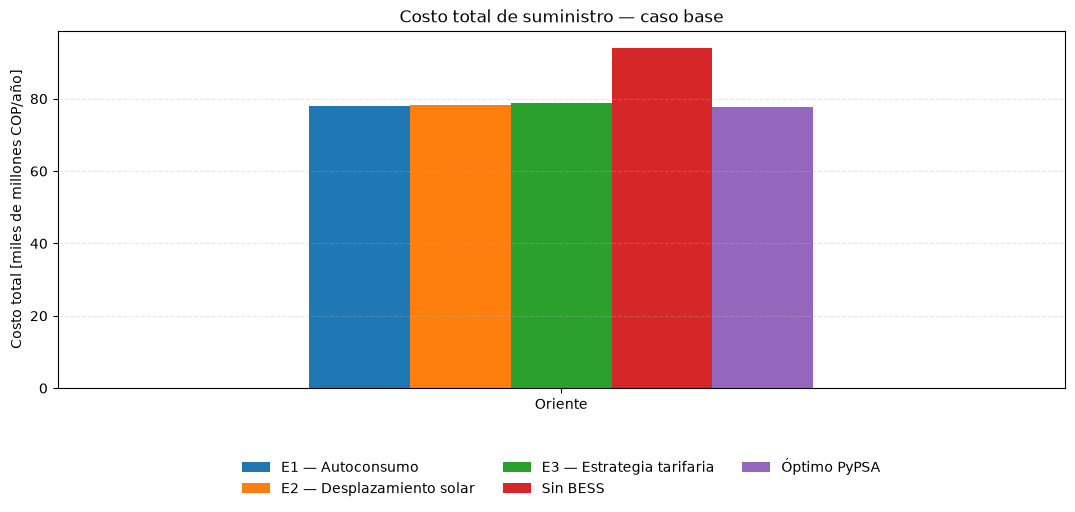

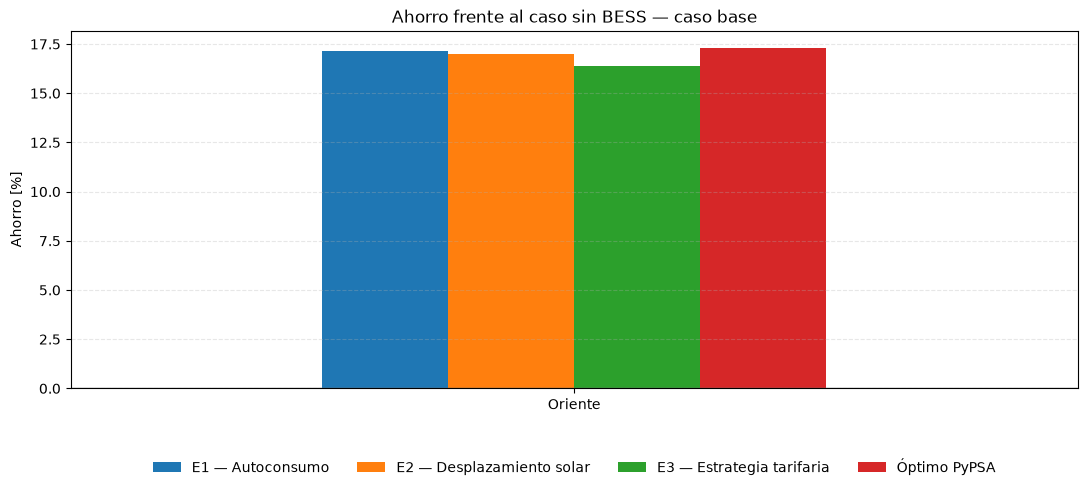

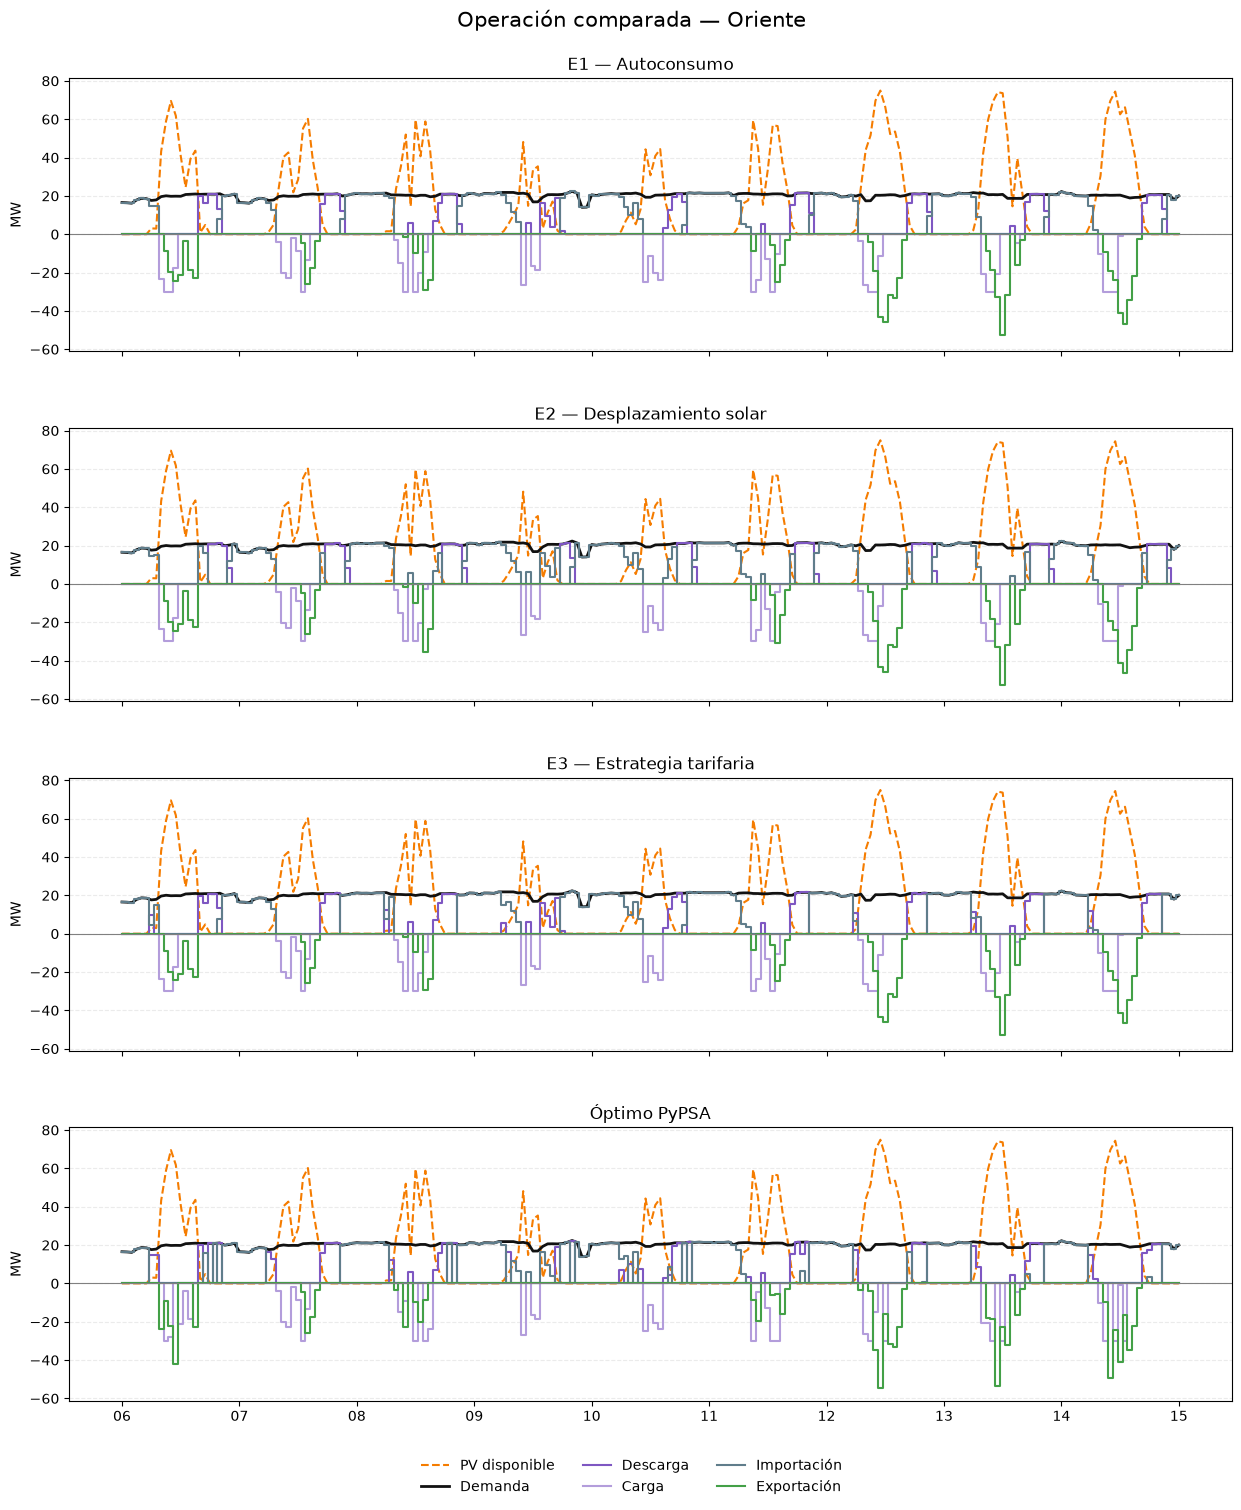

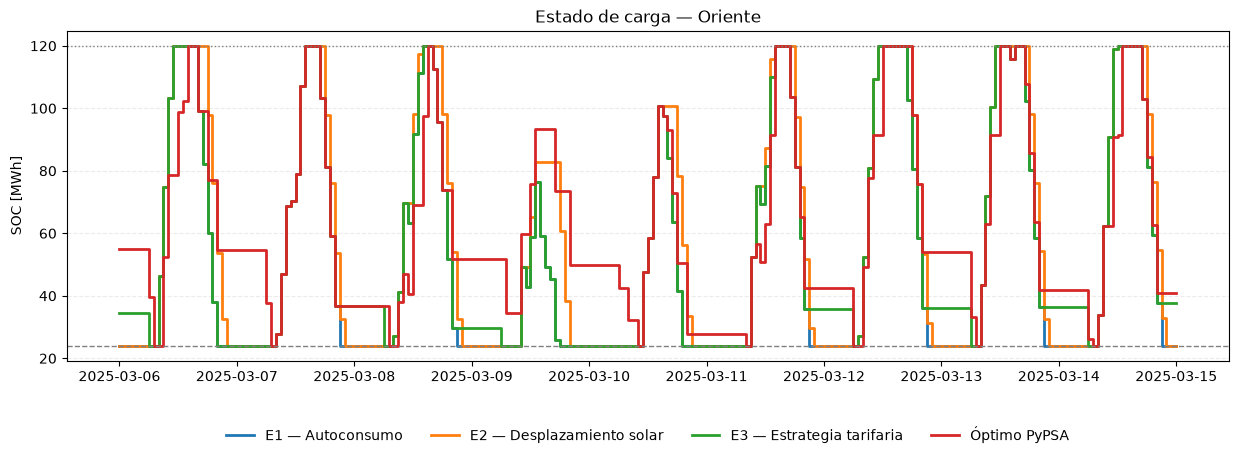

In [13]:
grafica_costos(
    resumen,
    'Costo total de suministro — caso base',
)

grafica_ahorros(
    resumen,
    'Ahorro frente al caso sin BESS — caso base',
)

estrategias_grafica = [
    e for e in [
        'E1 — Autoconsumo',
        'E2 — Desplazamiento solar',
        'E3 — Estrategia tarifaria',
        'Óptimo PyPSA',
    ]
    if (sitio, e) in resultados
]

grafica_operacion(
    resultados,
    sitio,
    estrategias_grafica,
    fecha_inicio_grafica,
    fecha_fin_grafica,
)

grafica_soc(
    resultados,
    sitio,
    estrategias_grafica,
    fecha_inicio_grafica,
    fecha_fin_grafica,
    SOC_min,
    SOC_max,
)

## 9. Costos de inversión y operación (CAPEX y OPEX)

Todo lo anterior compara las estrategias por su **costo operativo anual**: el PPA
solar, el cargo CND/ASIC, la energía comprada a la red y los excedentes vendidos.
Con esa métrica E1, E2 y E3 ahorran entre 17,3 % y 17,4 % frente al caso sin
batería.

Eso responde **cómo conviene operar la batería**, pero no responde la pregunta
anterior: **¿conviene tenerla?** Para eso faltan las dos piezas que el costo
operativo no incluye:

| | Qué es | Cuándo se paga |
|---|---|---|
| **CAPEX** | Inversión inicial: celdas, contenedor, PCS, transformador, obra civil y conexión | Una sola vez, en el año 0 |
| **OPEX** | Operación y mantenimiento | Todos los años de la vida útil |

### De dónde salen los supuestos

Los valores y sus fuentes están en `costos.py`, que los imprime con
`costos.ficha()`. En resumen:

| Parámetro | Valor | Fuente |
|---|---|---|
| CAPEX BESS, componente de energía | 220 USD/kWh | Lazard LCOE+ v18 (2025): capital DC 107–232 USD/kWh + EPC 28–116 USD/kWh |
| CAPEX BESS, componente de potencia | 120 USD/kW | Lazard: capital AC 25–67 USD/kW, más inversor y conexión |
| **CAPEX BESS equivalente a 4 h** | **250 USD/kWh** | Punto medio del rango 125 (Ember) – 192 (IRENA) – 321 (NREL *mid*) – 350 (NREL *high*) |
| OPEX BESS | 3,0 USD/kWh-año | Lazard: O&M de 3,0–8,0 USD/kWh-año; se toma el extremo bajo porque la aumentación se modela aparte, como reposición |
| Ciclos de vida / vida calendario | 6.000 ciclos / 15 años | Lazard (350 ciclos/año × 20 años) y NREL (15 años de vida calendario) |
| TRM | 4.052,86 COP/USD | Banco de la República, promedio de la TRM diaria de 2025 |
| Horizonte / WACC | 20 años / 10 % real | Lazard usa 20 años de vida de proyecto para almacenamiento |

La convención de partir el CAPEX en un componente de energía (USD/kWh) y uno de
potencia (USD/kW) es la de NREL, y sirve para que el modelo funcione con
cualquier duración: `costo [USD/kWh] = energía + potencia / horas`.

### Qué entra en la inversión y qué no

El caso base remunera la energía solar con un **PPA de 300 COP/kWh**. Bajo esa
figura la planta fotovoltaica **no es un activo del usuario**: es un contrato de
compra, y su costo ya está adentro de `Costo_total_suministro_COP`. Sumarle
además el CAPEX del PV sería contarla dos veces.

Por eso aquí **solo se invierte en el BESS**, que además es lo único que cambia
entre las cinco estrategias: las cinco tienen los mismos 100 MW de PV y la misma
demanda, y las cuatro con batería compran exactamente la misma batería. La
comparación se reduce a una pregunta: *el ahorro operativo de cada regla, ¿alcanza
para pagar la batería?*

> El análisis completo —con la variante de PV propio, el flujo de caja año a año
> y la sensibilidad al CAPEX— está en
> **`06_Comparacion_economica_5_escenarios.ipynb`**.

In [14]:
import costos

costos.ficha(
    power_MW=power_MW,
    capacity_MWh=capacity_MWh,
    pv_MW=pv_nominal_MW,
)

SUPUESTOS DE CAPEX Y OPEX
TRM                              : 3,126.08 COP/USD  (vigente al 2026-09-05)

BESS
  CAPEX componente de energía    : 220 USD/kWh
  CAPEX componente de potencia   : 120 USD/kW
  CAPEX equivalente a 4 h        : 250 USD/kWh
  OPEX                           : 3.0 USD/kWh-año (12 USD/kW-año a 4 h)
  Ciclos de vida                 : 7,200
  Vida calendario                : 20 años

PV  (solo si el PV es propio; bajo PPA no aplica)
  CAPEX                          : 850 USD/kW
  OPEX                           : 14 USD/kW-año

Financieros
  Horizonte                      : 20 años
  WACC real                      : 10%
  Degradación del recurso solar  : 0.5%/año
  Factor de recuperación de capital: 0.1175

CASO: PV 100 MW | BESS 30 MW / 120 MWh
  CAPEX BESS                     : 78.81 mil MM COP
  OPEX BESS anual                : 1.182 mil MM COP
  CAPEX BESS anualizado          : 9.26 mil MM COP/año
  CAPEX PV si fuera propio       : 212.32 mil MM COP

FUENTES

[NR

In [15]:
# El PV está bajo PPA, así que el contrafactual es 'Sin BESS': la pregunta que
# responde el VPN es si se paga la BATERÍA, no si se paga el proyecto entero.
economia = costos.evaluar(
    resumen,
    power_MW=power_MW,
    capacity_MWh=capacity_MWh,
    pv_MW=pv_nominal_MW,
    DoD=DoD,
    pv_propio=False,
)

MM = 1e9

vista = pd.DataFrame({
    'Estrategia': economia['Estrategia'],
    'Costo operativo': economia['Costo_operativo_anual_COP'] / MM,
    'CAPEX': economia['CAPEX_total_COP'] / MM,
    'OPEX/año': economia['OPEX_total_anual_COP'] / MM,
    'CAPEX anualizado': economia['CAPEX_anualizado_COP'] / MM,
    'CAE': economia['Costo_anual_equivalente_COP'] / MM,
    'VPN': economia['VPN_COP'] / MM,
    'TIR %': economia['TIR'] * 100,
    'LCOE COP/kWh': economia['Costo_nivelado_COP_kWh'],
})

print('Costos en miles de millones de COP · CAE = costo operativo + OPEX + CAPEX anualizado')
print('El CAPEX se anualiza sobre la vida del BESS, no sobre el horizonte.')

display(
    vista
    .style
    .hide(axis='index')
    .format({
        'Costo operativo': '{:,.2f}',
        'CAPEX': '{:,.2f}',
        'OPEX/año': '{:,.2f}',
        'CAPEX anualizado': '{:,.2f}',
        'CAE': '{:,.2f}',
        'VPN': '{:,.2f}',
        'TIR %': '{:,.2f}',
        'LCOE COP/kWh': '{:,.1f}',
    }, na_rep='—')
)

Costos en miles de millones de COP · CAE = costo operativo + OPEX + CAPEX anualizado
El CAPEX se anualiza sobre la vida del BESS, no sobre el horizonte.


Estrategia,Costo operativo,CAPEX,OPEX/año,CAPEX anualizado,CAE,VPN,TIR %,LCOE COP/kWh
Sin BESS,94.12,0.00,0.00,0.00,94.12,0.00,—,574.1
E1 — Autoconsumo,77.97,78.81,1.18,9.26,88.40,28.89,15.70,541.1
E2 — Desplazamiento solar,78.14,78.81,1.18,9.26,88.58,27.62,15.46,542.1
E3 — Estrategia tarifaria,78.70,78.81,1.18,9.26,89.14,23.56,14.68,545.5
Óptimo PyPSA,77.84,78.81,1.18,9.26,88.28,29.81,15.88,540.3


In [16]:
# ============================================================
# ¿SE PAGA LA BATERÍA?
# ============================================================

linea = '=' * 84
eco = economia.set_index('Estrategia')
referencia = eco.loc['Sin BESS', 'Costo_anual_equivalente_COP']

print(linea)
print('¿SE PAGA LA BATERÍA?')
print(linea)
print(f'Referencia — costo anual sin BESS : {referencia / MM:,.2f} mil MM COP/año')
print(f'CAPEX del BESS                    : '
      f'{eco.loc["E1 — Autoconsumo", "CAPEX_total_COP"] / MM:,.2f} mil MM COP '
      f'({costos.capex_bess_por_kwh_4h():,.0f} USD/kWh a 4 h)')
print(f'Vida del BESS                     : '
      f'{eco.loc["E1 — Autoconsumo", "Vida_BESS_anios"]:,.0f} años '
      f'({eco.loc["E1 — Autoconsumo", "Ciclos_equivalentes_anio"]:,.0f} ciclos/año; '
      f'manda el límite calendario, no el de ciclos)')
print()
print(f'{"Estrategia":<28} {"Ahorro op.":>11} {"Costo batería":>14} {"Balance":>10}')
print('-' * 84)

for e in [x for x in eco.index if x != 'Sin BESS']:
    ahorro = eco.loc[e, 'Beneficio_operativo_anual_COP'] / MM
    costo_activo = (eco.loc[e, 'CAPEX_anualizado_COP']
                    + eco.loc[e, 'OPEX_total_anual_COP']) / MM
    balance = ahorro - costo_activo
    print(f'{e:<28} {ahorro:11,.2f} {costo_activo:14,.2f} {balance:10,.2f}')

print()
print('Ahorro op.    = lo que la regla ahorra en un año de operación.')
print('Costo batería = CAPEX anualizado + OPEX de ese mismo año.')
print('Balance < 0   = la batería cuesta más de lo que ahorra.')
print()

mejor = eco.loc[[x for x in eco.index if x != 'Sin BESS'], 'VPN_COP'].max() / MM
peor = eco.loc[[x for x in eco.index if x != 'Sin BESS'], 'VPN_COP'].min() / MM

if mejor < 0:
    print(f'Ninguna estrategia alcanza VPN positivo: el rango va de {peor:,.2f} a '
          f'{mejor:,.2f} mil MM COP.')
    print(f'La diferencia entre la peor regla y la previsión perfecta, '
          f'{abs(mejor - peor):,.2f} mil MM COP, es el '
          f'{abs((mejor - peor) / peor) * 100:,.0f} % del VPN: elegir bien la regla '
          f'mejora el resultado,')
    print('pero no cambia el signo. Lo que lo cambiaría es el CAPEX.')
else:
    print(f'La mejor estrategia alcanza un VPN de {mejor:,.2f} mil MM COP.')

print(linea)

¿SE PAGA LA BATERÍA?
Referencia — costo anual sin BESS : 94.12 mil MM COP/año
CAPEX del BESS                    : 78.81 mil MM COP (250 USD/kWh a 4 h)
Vida del BESS                     : 20 años (330 ciclos/año; manda el límite calendario, no el de ciclos)

Estrategia                    Ahorro op.  Costo batería    Balance
------------------------------------------------------------------------------------
E1 — Autoconsumo                   16.16          10.44       5.72
E2 — Desplazamiento solar          15.99          10.44       5.55
E3 — Estrategia tarifaria          15.43          10.44       4.99
Óptimo PyPSA                       16.29          10.44       5.85

Ahorro op.    = lo que la regla ahorra en un año de operación.
Costo batería = CAPEX anualizado + OPEX de ese mismo año.
Balance < 0   = la batería cuesta más de lo que ahorra.

La mejor estrategia alcanza un VPN de 29.81 mil MM COP.


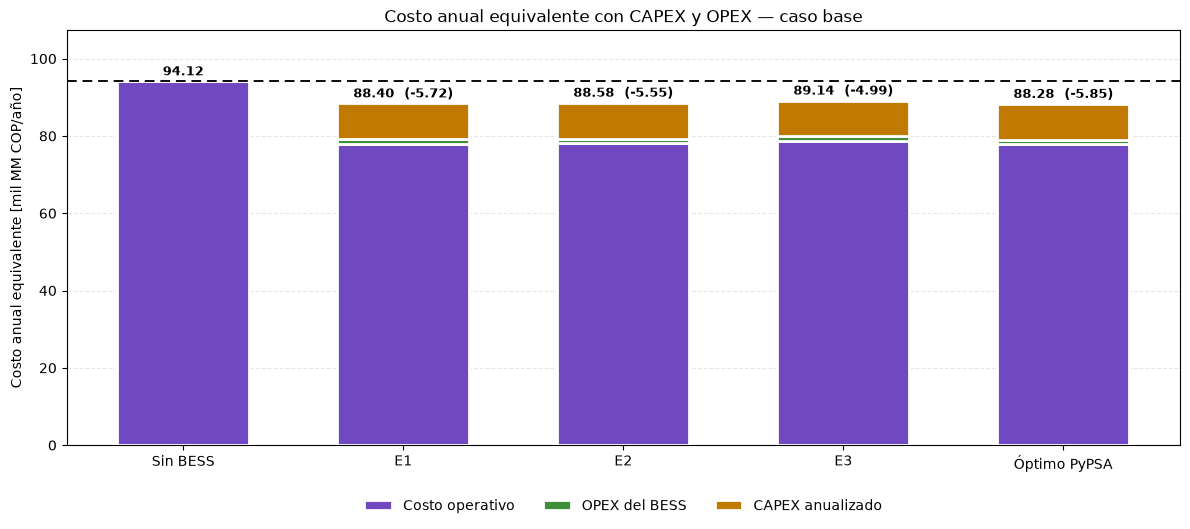

In [17]:
def grafica_costo_anual_equivalente(economia, titulo):
    '''Costo anual equivalente por estrategia, partido en sus tres componentes.

    La línea marca el escenario sin batería: cualquier barra que la supere es una
    inversión que no se paga.
    '''
    piezas = [
        ('Costo operativo', 'Costo_operativo_anual_COP', '#7048c0'),
        ('OPEX del BESS', 'OPEX_total_anual_COP', '#3f8f3a'),
        ('CAPEX anualizado', 'CAPEX_anualizado_COP', '#c07a00'),
    ]

    datos = economia.set_index('Estrategia')
    orden = list(datos.index)

    fig, ax = plt.subplots(figsize=(12, 5.4))
    x = np.arange(len(orden))
    base = np.zeros(len(orden))

    for nombre, columna, color in piezas:
        y = datos[columna].to_numpy() / 1e9
        ax.bar(x, y, bottom=base, width=0.6, color=color, label=nombre,
               edgecolor='white', linewidth=2, zorder=3)
        base = base + y

    referencia = datos.loc['Sin BESS', 'Costo_anual_equivalente_COP'] / 1e9
    ax.axhline(referencia, color='#0b0b0b', linewidth=1.4, linestyle=(0, (5, 3)),
               zorder=5)
    ax.annotate(f'Sin BESS — {referencia:,.2f}', xy=(len(orden) - 0.4, referencia),
                xytext=(0, 6), textcoords='offset points', ha='right', va='bottom',
                fontsize=9, fontweight='bold')

    for xi, total in enumerate(base):
        delta = total - referencia
        etiqueta = f'{total:,.2f}' if xi == 0 else f'{total:,.2f}  ({delta:+,.2f})'
        ax.text(xi, total + referencia * 0.008, etiqueta, ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', zorder=6)

    ax.set_xticks(x)
    ax.set_xticklabels([e.split(' — ')[0] for e in orden])
    ax.set_ylabel('Costo anual equivalente [mil MM COP/año]')
    ax.set_ylim(0, base.max() * 1.14)
    ax.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)
    ax.set_axisbelow(True)
    ax.set_title(titulo)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=3,
              frameon=False)

    plt.tight_layout()
    plt.show()


grafica_costo_anual_equivalente(
    economia,
    'Costo anual equivalente con CAPEX y OPEX — caso base',
)

## 10. Resumen para copiar al portapapeles

In [18]:
def reporte_para_chat(resumen, resultados, sitio):
    linea = '=' * 92
    salida = []

    salida.extend([
        linea,
        'PARÁMETROS DEL CASO',
        linea,
        f'PV nominal [MW]                 : {pv_nominal_MW:,.2f}',
        f'Tipo de demanda                 : {tipo_demanda}',
        f'Demanda media [MW]              : {df_base["Load_MW"].mean():,.2f}',
        f'Demanda máxima [MW]             : {df_base["Load_MW"].max():,.2f}',
        f'Demanda mínima [MW]             : {df_base["Load_MW"].min():,.2f}',
        f'Potencia BESS [MW]              : {power_MW:,.2f}',
        f'Capacidad BESS [MWh]            : {capacity_MWh:,.2f}',
        f'SOC mínimo / máximo [MWh]       : {SOC_min:,.2f} / {SOC_max:,.2f}',
        f'RTE / DoD                       : {eff_rt:.2%} / {DoD:.2%}',
        f'CERE [COP/MWh]                  : {cere_COP_MWh:,.2f}',
        f'FAZNI [COP/kWh]                 : {fazni_COP_kWh:,.4f}',
        f'Arranque y parada [COP/kWh]     : {arranque_parada_COP_kWh:,.2f}',
        f'CND/ASIC [COP/kW-mes]           : {cnd_asic_COP_kW_mes:,.2f}',
        f'Potencia máxima declarada [MW]  : {potencia_max_declarada_MW:,.2f}',
    ])

    cols = [
        'Estrategia',
        'PV_a_BESS_MWh',
        'Carga_desde_red_MWh',
        'Descarga_BESS_MWh',
        'Importacion_MWh',
        'Exportacion_MWh',
        'Vertimiento_MWh',
        'Costo_total_suministro_COP',
        'Ahorro_vs_sin_BESS_%',
    ]
    tabla = resumen[cols].copy()
    tabla['Costo_total_suministro_COP'] /= 1e9
    tabla = tabla.rename(
        columns={'Costo_total_suministro_COP': 'Costo_total_mil_MM_COP'}
    )

    salida.extend([
        '',
        linea,
        'RESUMEN DE ESTRATEGIAS',
        linea,
        tabla.to_string(
            index=False,
            float_format=lambda x: f'{x:,.2f}',
        ),
        '',
        linea,
        'DIAGNÓSTICO',
        linea,
    ])

    for (nombre_sitio, estrategia), df in resultados.items():
        if nombre_sitio != sitio or estrategia == 'Sin BESS':
            continue

        salida.append(
            f'{estrategia}: '
            f'SOC {df["SOC_MWh"].min():.2f}–{df["SOC_MWh"].max():.2f} MWh | '
            f'carga máx {df["Charge_MW"].max():.2f} MW | '
            f'descarga máx {df["Discharge_MW"].max():.2f} MW | '
            f'carga/descarga simultánea '
            f'{((df["Charge_MW"] > 1e-5) & (df["Discharge_MW"] > 1e-5)).sum()} h | '
            f'import/export simultánea '
            f'{((df["Grid_Import_MW"] > 1e-5) & (df["Grid_Export_MW"] > 1e-5)).sum()} h'
        )

    return '\n'.join(salida)


print(reporte_para_chat(resumen, resultados, sitio))

PARÁMETROS DEL CASO
PV nominal [MW]                 : 100.00
Tipo de demanda                 : variable
Demanda media [MW]              : 18.12
Demanda máxima [MW]             : 23.23
Demanda mínima [MW]             : 0.13
Potencia BESS [MW]              : 30.00
Capacidad BESS [MWh]            : 120.00
SOC mínimo / máximo [MWh]       : 24.00 / 120.00
RTE / DoD                       : 90.00% / 80.00%
CERE [COP/MWh]                  : 67,811.57
FAZNI [COP/kWh]                 : 3.2695
Arranque y parada [COP/kWh]     : 4.00
CND/ASIC [COP/kW-mes]           : 817.43
Potencia máxima declarada [MW]  : 100.00

RESUMEN DE ESTRATEGIAS
               Estrategia  PV_a_BESS_MWh  Carga_desde_red_MWh  Descarga_BESS_MWh  Importacion_MWh  Exportacion_MWh  Vertimiento_MWh  Costo_total_mil_MM_COP  Ahorro_vs_sin_BESS_%
                 Sin BESS           0.00                 0.00               0.00        97,364.05        77,364.25             0.00                   94.12                  0.00
         E1

In [ ]:
# ============================================================
# DESPACHO ÓPTIMO CON AUTOGENERACIÓN TÉRMICA
# ============================================================

# Extiende `optimizar_pypsa` con el tercer recurso del caso de estudio: un
# grupo de motogeneradores a gas detrás del medidor. El generador se conecta al
# bus del usuario, así que puede atender la demanda y cargar el BESS, pero NO
# tiene camino físico hacia el bus de exportación: los excedentes que salen al
# sistema siguen viniendo solo del PV.
#
# La diferencia con las heurísticas es exactamente la coordinación. La regla
# común del generador (en `generador_gas.despachar`) es miope: cubre la demanda
# residual cuando su costo variable es menor que el precio de compra, y nada
# más. El óptimo puede además sobredespacharlo para cargar la batería y guardar
# esa energía para las horas en que la demanda residual supera su capacidad.


def optimizar_pypsa_termico(
    df_base,
    power_MW,
    SOC_min,
    SOC_max,
    eff_c,
    eff_d,
    pv_nominal_MW,
    p_import_max_MW,
    p_export_max_MW,
    flota,
    disponibilidad_gas,
    escala_gas=1.0,
    gas_fijo_MW=None,
    con_minimos=True,
    solver_name='highs',
    c_epsilon_COP_MWh=1.0,
    tol=1e-6,
    mip_rel_gap=1e-7,
):
    if pypsa is None:
        raise ImportError(
            'PyPSA no está instalado. Ejecuta %pip install pypsa highspy '
            'y reinicia el kernel.'
        )

    data = (
        df_base
        .copy()
        .set_index('Fecha')
        .sort_index()
    )
    snapshots = data.index

    pv_p_nom = float(max(pv_nominal_MW, data['PV_MW'].max()))
    pv_pu = (data['PV_MW'] / pv_p_nom).clip(lower=0.0, upper=1.0)

    u_gas = pd.Series(
        np.asarray(disponibilidad_gas, dtype=float),
        index=snapshots,
    ).clip(lower=0.0, upper=1.0)

    n = pypsa.Network()
    n.set_snapshots(snapshots)

    n.add('Carrier', 'electricidad')
    n.add('Carrier', 'bateria')

    n.add('Bus', 'PV', carrier='electricidad')
    n.add('Bus', 'Usuario', carrier='electricidad')
    n.add('Bus', 'BESS', carrier='bateria')

    n.add(
        'Generator',
        'PV_disponible',
        bus='PV',
        p_nom=pv_p_nom,
        p_min_pu=0.0,
        p_max_pu=pv_pu,
        marginal_cost=0.0,
    )

    n.add(
        'Link',
        'PV_a_usuario',
        bus0='PV',
        bus1='Usuario',
        p_nom=pv_p_nom,
        p_min_pu=0.0,
        p_max_pu=1.0,
        efficiency=1.0,
    )

    n.add(
        'Generator',
        'Exportacion_PV',
        bus='PV',
        sign=-1,
        p_nom=p_export_max_MW,
        p_min_pu=0.0,
        p_max_pu=1.0,
        marginal_cost=-data['c_exp_COP_MWh'],
    )

    n.add(
        'Load',
        'Demanda',
        bus='Usuario',
        p_set=data['Load_MW'],
    )

    n.add(
        'Generator',
        'Importacion_red',
        bus='Usuario',
        p_nom=p_import_max_MW,
        p_min_pu=0.0,
        p_max_pu=1.0,
        marginal_cost=data['c_imp_COP_MWh'],
    )

    # Autogeneración térmica: la flota real, unidad por unidad.
    #
    # `flota` es un DataFrame indexado por unidad con P_disp_MW, P_min_MW y
    # CV_COP_MWh. Cada unidad se declara `committable` para que su mínimo
    # técnico sea una restricción de verdad y no un promedio: una unidad o está
    # apagada o entrega al menos su mínimo. Eso introduce una binaria por unidad
    # y hora, que es el precio de representar el activo como es.
    #
    # `gas_fijo_MW` congela el despacho de la flota en una trayectoria dada.
    # Sirve para descomponer el valor de la optimización: con la flota atada a
    # la regla miope, lo que el óptimo gana por encima de la mejor heurística es
    # solo mérito de la batería y del intercambio; la diferencia contra el
    # óptimo libre es el valor de coordinar el despacho térmico.
    for unidad in flota.index:
        p_disp = float(flota.loc[unidad, 'P_disp_MW']) * escala_gas
        if p_disp <= 0:
            continue
        p_min_pu = float(flota.loc[unidad, 'P_min_MW']) / float(flota.loc[unidad, 'P_disp_MW'])

        if gas_fijo_MW is not None:
            fijo = pd.Series(
                np.asarray(gas_fijo_MW[unidad], dtype=float) / p_disp,
                index=snapshots,
            ).clip(lower=0.0, upper=1.0)
            n.add(
                'Generator', f'Gas_{unidad}', bus='Usuario', p_nom=p_disp,
                p_min_pu=fijo, p_max_pu=fijo,
                marginal_cost=float(flota.loc[unidad, 'CV_COP_MWh']),
            )
        elif con_minimos:
            n.add(
                'Generator', f'Gas_{unidad}', bus='Usuario', p_nom=p_disp,
                committable=True,
                p_min_pu=p_min_pu,
                p_max_pu=u_gas,
                marginal_cost=float(flota.loc[unidad, 'CV_COP_MWh']),
            )
        else:
            n.add(
                'Generator', f'Gas_{unidad}', bus='Usuario', p_nom=p_disp,
                p_min_pu=0.0, p_max_pu=u_gas,
                marginal_cost=float(flota.loc[unidad, 'CV_COP_MWh']),
            )

    n.add(
        'Store',
        'BESS_store',
        bus='BESS',
        e_nom=SOC_max,
        e_min_pu=SOC_min / SOC_max,
        e_max_pu=1.0,
        e_cyclic=True,
        standing_loss=0.0,
    )

    n.add(
        'Link',
        'BESS_carga',
        bus0='Usuario',
        bus1='BESS',
        p_nom=power_MW,
        p_min_pu=0.0,
        p_max_pu=1.0,
        efficiency=eff_c,
        marginal_cost=c_epsilon_COP_MWh,
    )

    n.add(
        'Link',
        'BESS_descarga',
        bus0='BESS',
        bus1='Usuario',
        p_nom=power_MW / eff_d,
        p_min_pu=0.0,
        p_max_pu=1.0,
        efficiency=eff_d,
        marginal_cost=c_epsilon_COP_MWh * eff_d,
    )

    def restricciones_pcc(network, sns):
        m = network.model
        p = m.variables['Generator-p']

        # El argumento de por qué basta con estas horas no cambia al añadir el
        # generador: si hubiera importación y exportación simultáneas, bajar
        # ambas en delta cambia el costo en delta * (c_exp - c_imp) <= 0 y deja
        # los dos buses balanceados por el enlace PV -> usuario, sin tocar el
        # despacho térmico.
        puede_atar = (
            (data['c_exp_COP_MWh'] > data['c_imp_COP_MWh'])
            & (data['PV_MW'] > 0)
        ).reindex(sns).fillna(False).to_numpy()

        horas_pcc = pd.Index(pd.DatetimeIndex(sns)[puede_atar], name='snapshot')
        if len(horas_pcc) == 0:
            return

        p_import = p.sel(name='Importacion_red', snapshot=horas_pcc)
        p_export = p.sel(name='Exportacion_PV', snapshot=horas_pcc)

        modo_importacion = m.add_variables(
            binary=True,
            coords=[horas_pcc],
            name='PCC_modo_importacion',
        )

        m.add_constraints(
            p_import <= p_import_max_MW * modo_importacion,
            name='PCC_limite_importacion',
        )
        m.add_constraints(
            p_export <= p_export_max_MW * (1 - modo_importacion),
            name='PCC_limite_exportacion',
        )

    status, condition = n.optimize(
        solver_name=solver_name,
        extra_functionality=restricciones_pcc,
        solver_options={'mip_rel_gap': mip_rel_gap},
        log_to_console=False,
    )

    if status != 'ok' or condition != 'optimal':
        raise RuntimeError(
            f'PyPSA no encontró una solución óptima: {status} / {condition}'
        )

    resultado = data.reset_index()[
        [
            'Fecha',
            'PV_MW',
            'Load_MW',
            'Hora',
            'Franja_alta',
            'Franja_baja',
            'c_imp_COP_MWh',
            'c_ppa_COP_MWh',
            'c_exp_bruto_COP_MWh',
            'c_exp_COP_MWh',
        ]
    ].copy()

    pv_despachado = n.generators_t.p['PV_disponible'].to_numpy()
    pv_a_usuario = n.links_t.p0['PV_a_usuario'].to_numpy()
    importacion = n.generators_t.p['Importacion_red'].to_numpy()
    exportacion = n.generators_t.p['Exportacion_PV'].to_numpy()
    carga = n.links_t.p0['BESS_carga'].to_numpy()
    descarga = -n.links_t.p1['BESS_descarga'].to_numpy()
    soc = n.stores_t.e['BESS_store'].to_numpy()

    gas = np.zeros(len(resultado))
    gas_unidades = {}
    for unidad in flota.index:
        nombre = f'Gas_{unidad}'
        if nombre in n.generators.index:
            p = n.generators_t.p[nombre].to_numpy()
        else:
            p = np.zeros(len(resultado))
        gas_unidades[unidad] = p
        gas = gas + p

    # Descomposición contable del bus del usuario, con orden de mérito
    # PV -> gas -> red, para poder comparar columna a columna con las
    # heurísticas. Es atribución para reportar: la optimización se hace sobre
    # el balance del bus, no sobre esta partición.
    load = resultado['Load_MW'].to_numpy()

    pv_to_load = np.minimum(pv_a_usuario, load)
    pv_restante = np.maximum(0.0, pv_a_usuario - pv_to_load)

    residual_pv = np.maximum(0.0, load - pv_to_load)
    gas_to_load = np.minimum(gas, residual_pv)
    gas_restante = np.maximum(0.0, gas - gas_to_load)

    charge_from_pv = np.minimum(carga, pv_restante)
    charge_from_gas = np.minimum(carga - charge_from_pv, gas_restante)
    charge_from_grid = np.maximum(0.0, carga - charge_from_pv - charge_from_gas)

    residual_gas = np.maximum(0.0, residual_pv - gas_to_load)
    grid_to_load = np.maximum(0.0, residual_gas - descarga)

    resultado['PV_Dispatch_MW'] = pv_despachado
    resultado['PV_to_Load_MW'] = pv_to_load
    resultado['PV_Net_Surplus_MW'] = np.maximum(0.0, resultado['PV_MW'] - resultado['Load_MW'])
    resultado['Residual_Load_MW'] = np.maximum(0.0, resultado['Load_MW'] - resultado['PV_MW'])
    for unidad, p in gas_unidades.items():
        resultado[f'Gas_{unidad}_MW'] = p
    resultado['Gas_MW'] = gas
    resultado['Gas_to_Load_MW'] = gas_to_load
    resultado['Charge_from_PV_MW'] = charge_from_pv
    resultado['Charge_from_Gas_MW'] = charge_from_gas
    resultado['Charge_from_Grid_MW'] = charge_from_grid
    resultado['Charge_MW'] = carga
    resultado['Discharge_MW'] = descarga
    resultado['SOC_MWh'] = soc
    resultado['Grid_to_Load_MW'] = grid_to_load
    resultado['Grid_Import_MW'] = importacion
    resultado['Grid_Export_MW'] = exportacion
    resultado['Curtailment_MW'] = np.maximum(
        0.0,
        resultado['PV_MW'].to_numpy() - pv_despachado,
    )

    resultado.attrs['SOC_inicial_MWh'] = float(soc[-1])
    resultado.attrs['SOC_final_MWh'] = float(soc[-1])

    simultaneo_bess = (
        (resultado['Charge_MW'] > tol) & (resultado['Discharge_MW'] > tol)
    ).sum()
    simultaneo_red = (
        (resultado['Grid_Import_MW'] > tol) & (resultado['Grid_Export_MW'] > tol)
    ).sum()

    if simultaneo_bess:
        raise ValueError(
            f'Óptimo térmico: {simultaneo_bess} horas con carga y descarga simultánea.'
        )
    if simultaneo_red:
        raise ValueError(
            f'Óptimo térmico: {simultaneo_red} horas con importación y exportación simultáneas.'
        )

    error_bus_pv = pv_despachado - pv_a_usuario - exportacion
    if np.max(np.abs(error_bus_pv)) > 1e-4:
        raise ValueError('Óptimo térmico: falla el balance del bus PV.')

    # Balance del bus del usuario, con el generador dentro.
    error_bus_usuario = (
        pv_a_usuario + importacion + gas + descarga - load - carga
    )
    if np.max(np.abs(error_bus_usuario)) > 1e-4:
        raise ValueError('Óptimo térmico: falla el balance del bus del usuario.')

    for unidad, p in gas_unidades.items():
        p_disp = float(flota.loc[unidad, 'P_disp_MW']) * escala_gas
        p_min = float(flota.loc[unidad, 'P_min_MW']) * escala_gas
        if (p > p_disp * u_gas.to_numpy() + 1e-5).any():
            raise ValueError(f'Óptimo térmico: {unidad} excede su disponibilidad.')
        if con_minimos and gas_fijo_MW is None:
            if ((p > 1e-5) & (p < p_min - 1e-5)).any():
                raise ValueError(f'Óptimo térmico: {unidad} opera bajo su mínimo técnico.')

    return n, resultado
